## IMPORT LIBRARIES

In [7]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## LOAD DATASET

In [12]:
df = pd.read_csv("C:/Windows/System32/project/superstore/dataset/Sample - Superstore.csv", encoding='cp1252')

## DATA UNDERSTANDING

In [13]:
# Display first 5 rows
display(df.head())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column information
print("\nColumn Names:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Dataset information
print("\nDataset Info:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all').T)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Dataset Shape: (9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data Types:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-N

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,9994.0,NaN,NaN,NaN,4997.5,2885.163629,1.0,2499.25,4997.5,7495.75,9994.0
Order ID,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1237,9/5/2016,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2015,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## DATA QUALITY ASSESSMENT

In [14]:
# ==========================================
# 1. CHECK MISSING VALUES
# ==========================================

missing_values = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values.sort_values(
    by='Missing Values',
    ascending=False
)

print("Missing Values Assessment:")
display(missing_values)

Missing Values Assessment:


,Missing Values,Percentage (%)
Row ID,0,0.0
Order ID,0,0.0
Order Date,0,0.0
Ship Date,0,0.0
Ship Mode,0,0.0
Customer ID,0,0.0
Customer Name,0,0.0
Segment,0,0.0
Country,0,0.0
City,0,0.0


In [15]:
# ==========================================
# 2. CHECK DUPLICATE RECORDS
# ==========================================

duplicate_count = df.duplicated().sum()

print(f"Total Duplicate Rows: {duplicate_count}")
print(f"Total Unique Rows: {df.drop_duplicates().shape[0]}")

Total Duplicate Rows: 0
Total Unique Rows: 9994


In [16]:
# ==========================================
# 3. CHECK DATE VALIDITY
# ==========================================

order_date = pd.to_datetime(
    df['Order Date'],
    format='%m/%d/%Y',
    errors='coerce'
)

ship_date = pd.to_datetime(
    df['Ship Date'],
    format='%m/%d/%Y',
    errors='coerce'
)

print("Invalid Order Date:", order_date.isna().sum())
print("Invalid Ship Date:", ship_date.isna().sum())

# Check shipping date before order date
invalid_shipping = (ship_date < order_date).sum()

print("Ship Date Before Order Date:", invalid_shipping)

Invalid Order Date: 0
Invalid Ship Date: 0
Ship Date Before Order Date: 0


In [17]:
# ==========================================
# 4. CHECK NUMERICAL VALUES
# ==========================================

numerical_checks = {
    'Negative Sales': (df['Sales'] < 0).sum(),
    'Zero Sales': (df['Sales'] == 0).sum(),
    'Invalid Quantity': (df['Quantity'] <= 0).sum(),
    'Discount Below 0': (df['Discount'] < 0).sum(),
    'Discount Above 1': (df['Discount'] > 1).sum(),
    'Negative Profit': (df['Profit'] < 0).sum()
}

numerical_assessment = pd.DataFrame(
    numerical_checks.items(),
    columns=['Check', 'Total Records']
)

display(numerical_assessment)

,Check,Total Records
0,Negative Sales,0
1,Zero Sales,0
2,Invalid Quantity,0
3,Discount Below 0,0
4,Discount Above 1,0
5,Negative Profit,1871


In [18]:
# ==========================================
# INVESTIGATE NEGATIVE PROFIT
# ==========================================

negative_profit = df[df['Profit'] < 0]

print("Total Negative Profit Records:",
      len(negative_profit))

print("\nNegative Profit by Category:")

display(
    negative_profit.groupby('Category')
    .agg(
        Total_Records=('Profit', 'count'),
        Total_Loss=('Profit', 'sum')
    )
    .sort_values('Total_Loss')
)

print("\nNegative Profit by Sub-Category:")

display(
    negative_profit.groupby('Sub-Category')
    .agg(
        Total_Records=('Profit', 'count'),
        Total_Loss=('Profit', 'sum')
    )
    .sort_values('Total_Loss')
)

Total Negative Profit Records: 1871

Negative Profit by Category:


,Total_Records,Total_Loss
Category,,
Furniture,714,-60936.1090
Office Supplies,886,-56615.2585
Technology,271,-38579.9182



Negative Profit by Sub-Category:


,Total_Records,Total_Loss
Sub-Category,,
Binders,613,-38510.4964
Tables,203,-32412.1483
Machines,44,-30118.6682
Bookcases,109,-12152.2060
Chairs,235,-9880.8413
Appliances,67,-8629.6412
Phones,136,-7530.6235
Furnishings,167,-6490.9134
Storage,161,-6426.3038


## DATA CLEANING

In [19]:
# ==========================================
# 1. CREATE CLEAN DATASET
# ==========================================

df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Clean Dataset Shape:", df_clean.shape)

Original Dataset Shape: (9994, 21)
Clean Dataset Shape: (9994, 21)


In [20]:
# ==========================================
# 2. CONVERT DATA TYPES
# ==========================================

# Convert date columns
df_clean['Order Date'] = pd.to_datetime(
    df_clean['Order Date'],
    format='%m/%d/%Y'
)

df_clean['Ship Date'] = pd.to_datetime(
    df_clean['Ship Date'],
    format='%m/%d/%Y'
)

# Convert Postal Code to string
df_clean['Postal Code'] = df_clean['Postal Code'].astype('string')

print("Data Types After Conversion:")
display(df_clean.dtypes)

Data Types After Conversion:


Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code      string[python]
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

In [21]:
# ==========================================
# 3. VALIDATE CLEANED DATASET
# ==========================================

print("Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate Records:")
print(df_clean.duplicated().sum())

print("\nDate Data Types:")
print(df_clean[['Order Date', 'Ship Date']].dtypes)

print("\nPostal Code Data Type:")
print(df_clean['Postal Code'].dtype)

Dataset Shape: (9994, 21)

Missing Values:
0

Duplicate Records:
0

Date Data Types:
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

Postal Code Data Type:
string


In [22]:
# ==========================================
# 4. DATASET COMPARISON
# ==========================================

comparison = pd.DataFrame({
    'Original': df.dtypes.astype(str),
    'Cleaned': df_clean.dtypes.astype(str)
})

display(comparison)

,Original,Cleaned
Row ID,int64,int64
Order ID,object,object
Order Date,object,datetime64[ns]
Ship Date,object,datetime64[ns]
Ship Mode,object,object
Customer ID,object,object
Customer Name,object,object
Segment,object,object
Country,object,object
City,object,object


In [23]:
# ==========================================
# 5. SAVE CLEANED DATASET
# ==========================================

df_clean.to_csv(
    'C:/Windows/System32/project/superstore/dataset/superstore_cleaned.csv',
    index=False
)

print("Cleaned dataset successfully saved!")

Cleaned dataset successfully saved!


## EXPLORATORY DATA ANALYSIS (EDA)

In [24]:
# ==========================================
#  UNIVARIATE ANALYSIS
#  DESCRIPTIVE STATISTICS
# ==========================================

numerical_columns = [
    'Sales',
    'Profit',
    'Quantity',
    'Discount'
]

numerical_summary = df_clean[numerical_columns].describe().T

display(numerical_summary)

,count,mean,std,min,25%,50%,75%,max
Sales,9994.0,229.858001,623.245101,0.444,17.28000,54.4900,209.940,22638.480
Profit,9994.0,28.656896,234.260108,-6599.978,1.72875,8.6665,29.364,8399.976
Quantity,9994.0,3.789574,2.225110,1.000,2.00000,3.0000,5.000,14.000
Discount,9994.0,0.156203,0.206452,0.000,0.00000,0.2000,0.200,0.800


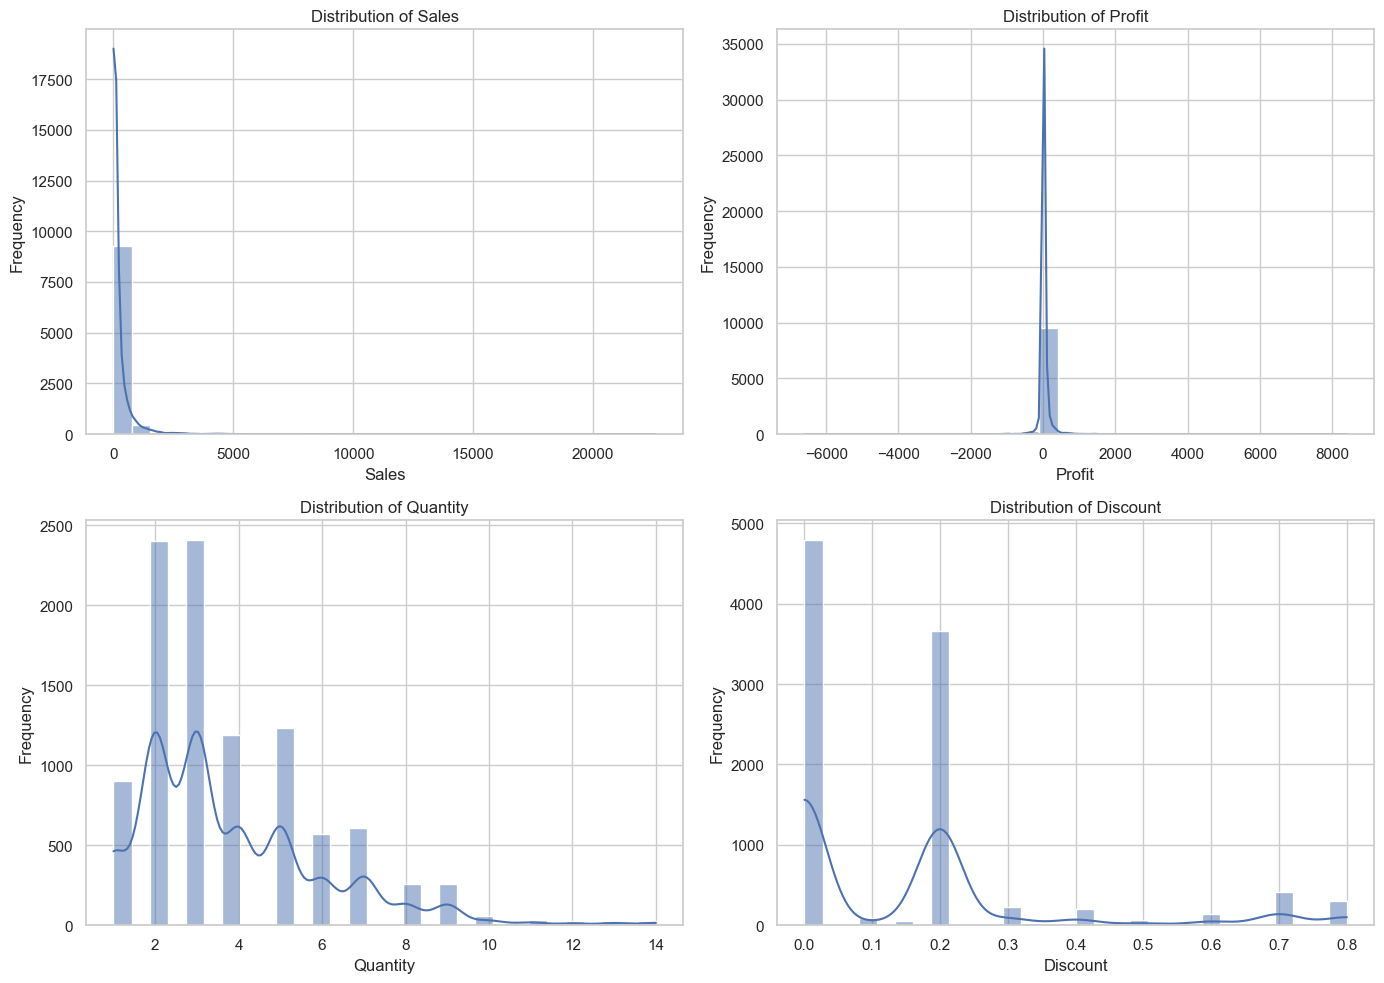

In [25]:
# ==========================================
#  NUMERICAL DISTRIBUTION
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for column, ax in zip(numerical_columns, axes.flatten()):
    sns.histplot(
        data=df_clean,
        x=column,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f'Distribution of {column}', fontsize=12)
    ax.set_xlabel(column)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

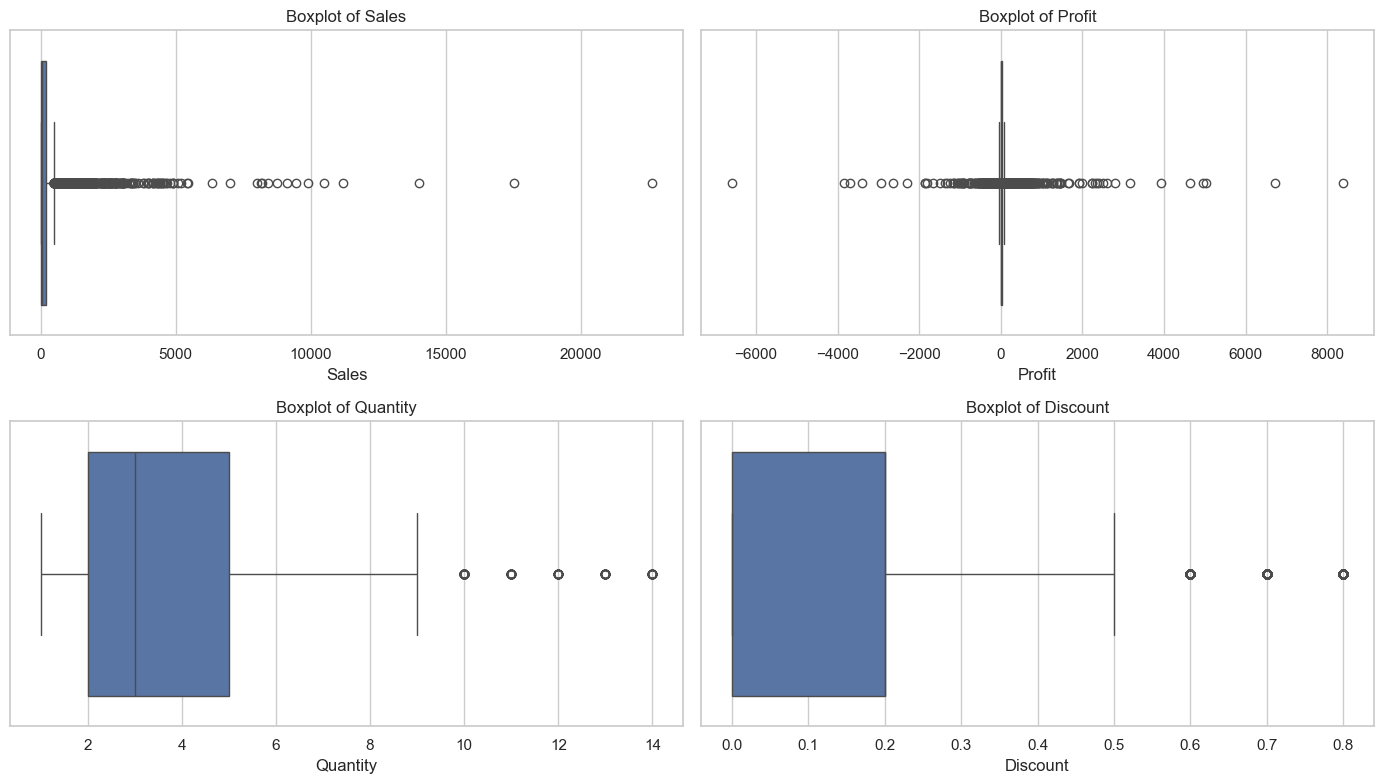

In [26]:
# ==========================================
# OUTLIER DETECTION
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for column, ax in zip(numerical_columns, axes.flatten()):
    sns.boxplot(
        data=df_clean,
        x=column,
        ax=ax
    )

    ax.set_title(f'Boxplot of {column}', fontsize=12)

plt.tight_layout()
plt.show()

In [27]:
# ==========================================
# DISTRIBUTION ANALYSIS
# ==========================================

distribution_summary = pd.DataFrame({
    'Skewness': df_clean[numerical_columns].skew(),
    'Kurtosis': df_clean[numerical_columns].kurtosis()
})

display(distribution_summary.round(3))

,Skewness,Kurtosis
Sales,12.973,305.312
Profit,7.561,397.189
Quantity,1.279,1.992
Discount,1.684,2.410


In [28]:
# ==========================================
# OUTLIER DETECTION USING IQR
# ==========================================

outlier_summary = []

for column in numerical_columns:

    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    outlier_summary.append({
        'Variable': column,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage (%)': (
            len(outliers) / len(df_clean)
        ) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary.round(3))

,Variable,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,Sales,-271.710,498.930,1167,11.677
1,Profit,-39.724,70.817,1881,18.821
2,Quantity,-2.500,9.500,170,1.701
3,Discount,-0.300,0.500,856,8.565


In [29]:
# ==========================================
# CATEGORICAL ANALYSIS
# CATEGORY DISTRIBUTION
# ==========================================

categorical_columns = [
    'Segment',
    'Category',
    'Sub-Category',
    'Region',
    'Ship Mode'
]

for column in categorical_columns:

    print(f"\nDistribution of {column}:")

    distribution = pd.DataFrame({
        'Count': df_clean[column].value_counts(),
        'Percentage (%)': (
            df_clean[column].value_counts(normalize=True) * 100
        )
    })

    display(distribution.round(2))


Distribution of Segment:


,Count,Percentage (%)
Segment,,
Consumer,5191,51.94
Corporate,3020,30.22
Home Office,1783,17.84



Distribution of Category:


,Count,Percentage (%)
Category,,
Office Supplies,6026,60.30
Furniture,2121,21.22
Technology,1847,18.48



Distribution of Sub-Category:


,Count,Percentage (%)
Sub-Category,,
Binders,1523,15.24
Paper,1370,13.71
Furnishings,957,9.58
Phones,889,8.90
Storage,846,8.47
Art,796,7.96
Accessories,775,7.75
Chairs,617,6.17
Appliances,466,4.66



Distribution of Region:


,Count,Percentage (%)
Region,,
West,3203,32.05
East,2848,28.50
Central,2323,23.24
South,1620,16.21



Distribution of Ship Mode:


,Count,Percentage (%)
Ship Mode,,
Standard Class,5968,59.72
Second Class,1945,19.46
First Class,1538,15.39
Same Day,543,5.43


In [30]:
# ==========================================
# BIVARIATE ANALYSIS
# SALES & PROFIT BY CATEGORY
# ==========================================

category_performance = (
    df_clean
    .groupby('Category')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Average_Sales=('Sales', 'mean'),
        Average_Profit=('Profit', 'mean'),
        Total_Quantity=('Quantity', 'sum'),
        Total_Orders=('Order ID', 'nunique')
    )
    .sort_values('Total_Sales', ascending=False)
)

display(category_performance.round(2))

,Total_Sales,Total_Profit,Average_Sales,Average_Profit,Total_Quantity,Total_Orders
Category,,,,,,
Technology,836154.03,145454.95,452.71,78.75,6939,1544
Furniture,741999.80,18451.27,349.83,8.70,8028,1764
Office Supplies,719047.03,122490.80,119.32,20.33,22906,3742


In [31]:
# ==========================================
# PROFIT MARGIN BY CATEGORY
# ==========================================

category_performance['Profit_Margin (%)'] = (
    category_performance['Total_Profit']
    / category_performance['Total_Sales']
) * 100

display(category_performance.round(2))

,Total_Sales,Total_Profit,Average_Sales,Average_Profit,Total_Quantity,Total_Orders,Profit_Margin (%)
Category,,,,,,,
Technology,836154.03,145454.95,452.71,78.75,6939,1544,17.40
Furniture,741999.80,18451.27,349.83,8.70,8028,1764,2.49
Office Supplies,719047.03,122490.80,119.32,20.33,22906,3742,17.04


In [32]:
# ==========================================
# SALES & PROFIT BY REGION
# ==========================================

region_performance = (
    df_clean
    .groupby('Region')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Average_Sales=('Sales', 'mean'),
        Average_Profit=('Profit', 'mean'),
        Total_Quantity=('Quantity', 'sum'),
        Total_Orders=('Order ID', 'nunique')
    )
    .sort_values('Total_Sales', ascending=False)
)

region_performance['Profit_Margin (%)'] = (
    region_performance['Total_Profit']
    / region_performance['Total_Sales']
) * 100

display(region_performance.round(2))

,Total_Sales,Total_Profit,Average_Sales,Average_Profit,Total_Quantity,Total_Orders,Profit_Margin (%)
Region,,,,,,,
West,725457.82,108418.45,226.49,33.85,12266,1611,14.94
East,678781.24,91522.78,238.34,32.14,10618,1401,13.48
Central,501239.89,39706.36,215.77,17.09,8780,1175,7.92
South,391721.90,46749.43,241.80,28.86,6209,822,11.93


In [33]:
# ==========================================
# SALES & PROFIT BY CUSTOMER SEGMENT
# ==========================================

segment_performance = (
    df_clean
    .groupby('Segment')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Average_Sales=('Sales', 'mean'),
        Average_Profit=('Profit', 'mean'),
        Total_Quantity=('Quantity', 'sum'),
        Total_Orders=('Order ID', 'nunique'),
        Total_Customers=('Customer ID', 'nunique')
    )
    .sort_values('Total_Sales', ascending=False)
)

segment_performance['Profit_Margin (%)'] = (
    segment_performance['Total_Profit']
    / segment_performance['Total_Sales']
) * 100

display(segment_performance.round(2))

,Total_Sales,Total_Profit,Average_Sales,Average_Profit,Total_Quantity,Total_Orders,Total_Customers,Profit_Margin (%)
Segment,,,,,,,,
Consumer,1161401.34,134119.21,223.73,25.84,19521,2586,409,11.55
Corporate,706146.37,91979.13,233.82,30.46,11608,1514,236,13.03
Home Office,429653.15,60298.68,240.97,33.82,6744,909,148,14.03


In [34]:
# ==========================================
#  TIME SERIES ANALYSIS
#  MONTHLY SALES & PROFIT TREND
# ==========================================

monthly_performance = (
    df_clean
    .set_index('Order Date')
    .resample('MS')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order ID', 'nunique'),
        Total_Quantity=('Quantity', 'sum')
    )
)

display(monthly_performance.round(2))

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
Order Date,,,,
2014-01-01,14236.90,2450.19,32,284
2014-02-01,4519.89,862.31,28,159
2014-03-01,55691.01,498.73,71,585
2014-04-01,28295.34,3488.84,66,536
2014-05-01,23648.29,2738.71,69,466
2014-06-01,34595.13,4976.52,66,521
2014-07-01,33946.39,-841.48,65,550
2014-08-01,27909.47,5318.10,72,609
2014-09-01,81777.35,8328.10,130,1000


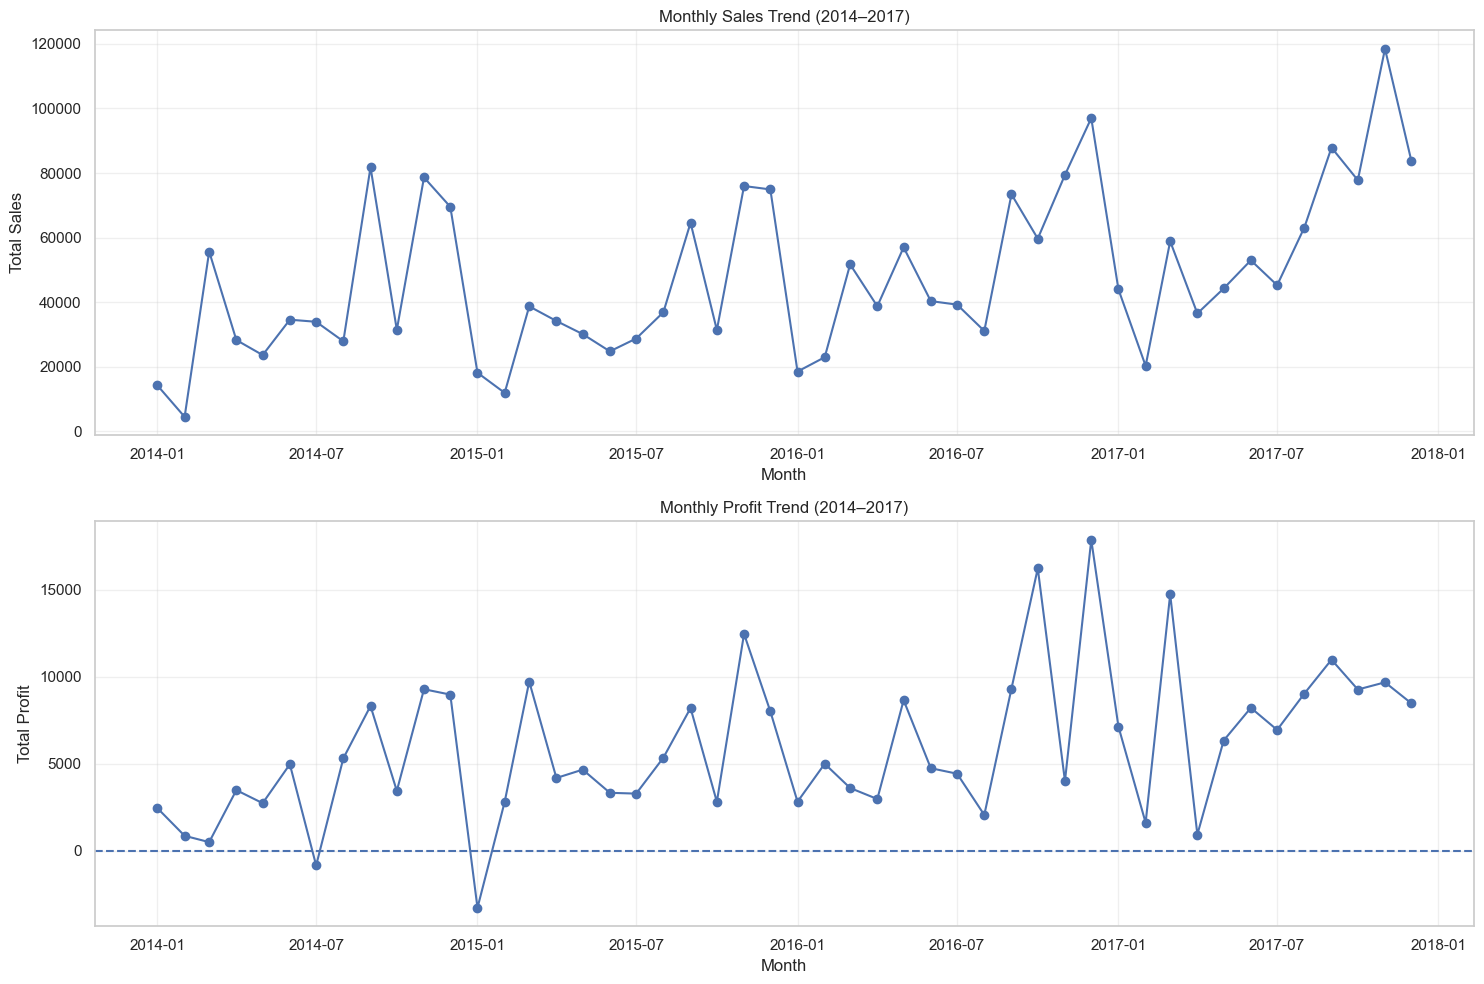

In [35]:
# ==========================================
# MONTHLY SALES & PROFIT VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Monthly Sales Trend
axes[0].plot(
    monthly_performance.index,
    monthly_performance['Total_Sales'],
    marker='o'
)

axes[0].set_title('Monthly Sales Trend (2014–2017)')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Total Sales')
axes[0].grid(True, alpha=0.3)

# Monthly Profit Trend
axes[1].plot(
    monthly_performance.index,
    monthly_performance['Total_Profit'],
    marker='o'
)

axes[1].axhline(y=0, linestyle='--')
axes[1].set_title('Monthly Profit Trend (2014–2017)')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Total Profit')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
# ==========================================
# YEARLY SALES & PROFIT ANALYSIS
# ==========================================

yearly_performance = (
    df_clean
    .groupby(df_clean['Order Date'].dt.year)
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order ID', 'nunique'),
        Total_Quantity=('Quantity', 'sum'),
        Total_Customers=('Customer ID', 'nunique')
    )
)

yearly_performance['Profit_Margin (%)'] = (
    yearly_performance['Total_Profit']
    / yearly_performance['Total_Sales']
) * 100

display(yearly_performance.round(2))

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Total_Customers,Profit_Margin (%)
Order Date,,,,,,
2014,484247.50,49543.97,969,7581,595,10.23
2015,470532.51,61618.60,1038,7979,573,13.10
2016,609205.60,81795.17,1315,9837,638,13.43
2017,733215.26,93439.27,1687,12476,693,12.74


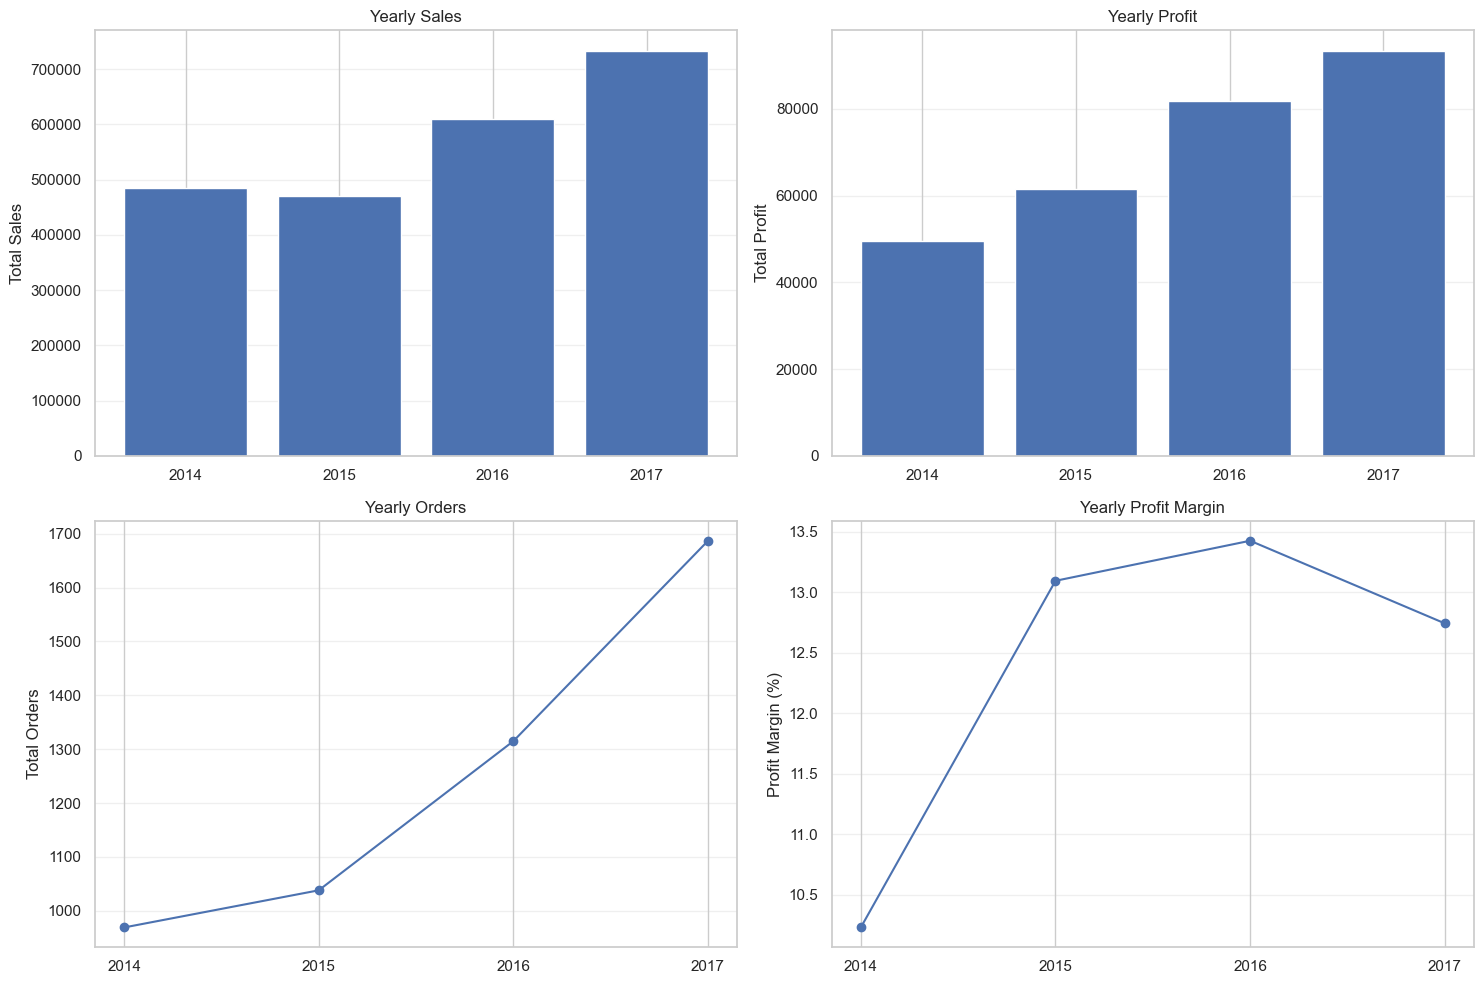

In [37]:
# ==========================================
# YEARLY PERFORMANCE VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Yearly Sales
axes[0, 0].bar(
    yearly_performance.index.astype(str),
    yearly_performance['Total_Sales']
)
axes[0, 0].set_title('Yearly Sales')
axes[0, 0].set_ylabel('Total Sales')

# 2. Yearly Profit
axes[0, 1].bar(
    yearly_performance.index.astype(str),
    yearly_performance['Total_Profit']
)
axes[0, 1].set_title('Yearly Profit')
axes[0, 1].set_ylabel('Total Profit')

# 3. Yearly Orders
axes[1, 0].plot(
    yearly_performance.index.astype(str),
    yearly_performance['Total_Orders'],
    marker='o'
)
axes[1, 0].set_title('Yearly Orders')
axes[1, 0].set_ylabel('Total Orders')

# 4. Profit Margin
axes[1, 1].plot(
    yearly_performance.index.astype(str),
    yearly_performance['Profit_Margin (%)'],
    marker='o'
)
axes[1, 1].set_title('Yearly Profit Margin')
axes[1, 1].set_ylabel('Profit Margin (%)')

for ax in axes.flat:
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [39]:
# ==========================================
#  DISCOUNT VS SALES & PROFIT ANALYSIS
#  DISCOUNT PERFORMANCE ANALYSIS
# ==========================================

discount_performance = (
    df_clean
    .groupby('Discount')
    .agg(
        Total_Order_Lines=('Order ID', 'count'),
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Average_Sales=('Sales', 'mean'),
        Average_Profit=('Profit', 'mean'),
        Total_Quantity=('Quantity', 'sum')
    )
    .sort_index()
)

discount_performance['Profit_Margin (%)'] = (
    discount_performance['Total_Profit']
    / discount_performance['Total_Sales']
) * 100

display(discount_performance.round(2))

,Total_Order_Lines,Total_Sales,Total_Profit,Average_Sales,Average_Profit,Total_Quantity,Profit_Margin (%)
Discount,,,,,,,
0.00,4798,1087908.47,320987.60,226.74,66.90,18267,29.51
0.10,94,54369.35,9029.18,578.40,96.06,373,16.61
0.15,52,27558.52,1418.99,529.97,27.29,198,5.15
0.20,3657,764594.37,90337.31,209.08,24.70,13660,11.82
0.30,227,103226.66,-10369.28,454.74,-45.68,849,-10.05
0.32,27,14493.46,-2391.14,536.79,-88.56,105,-16.50
0.40,206,116417.78,-23057.05,565.13,-111.93,786,-19.81
0.45,11,5484.97,-2493.11,498.63,-226.65,45,-45.45
0.50,66,58918.54,-20506.43,892.71,-310.70,241,-34.80


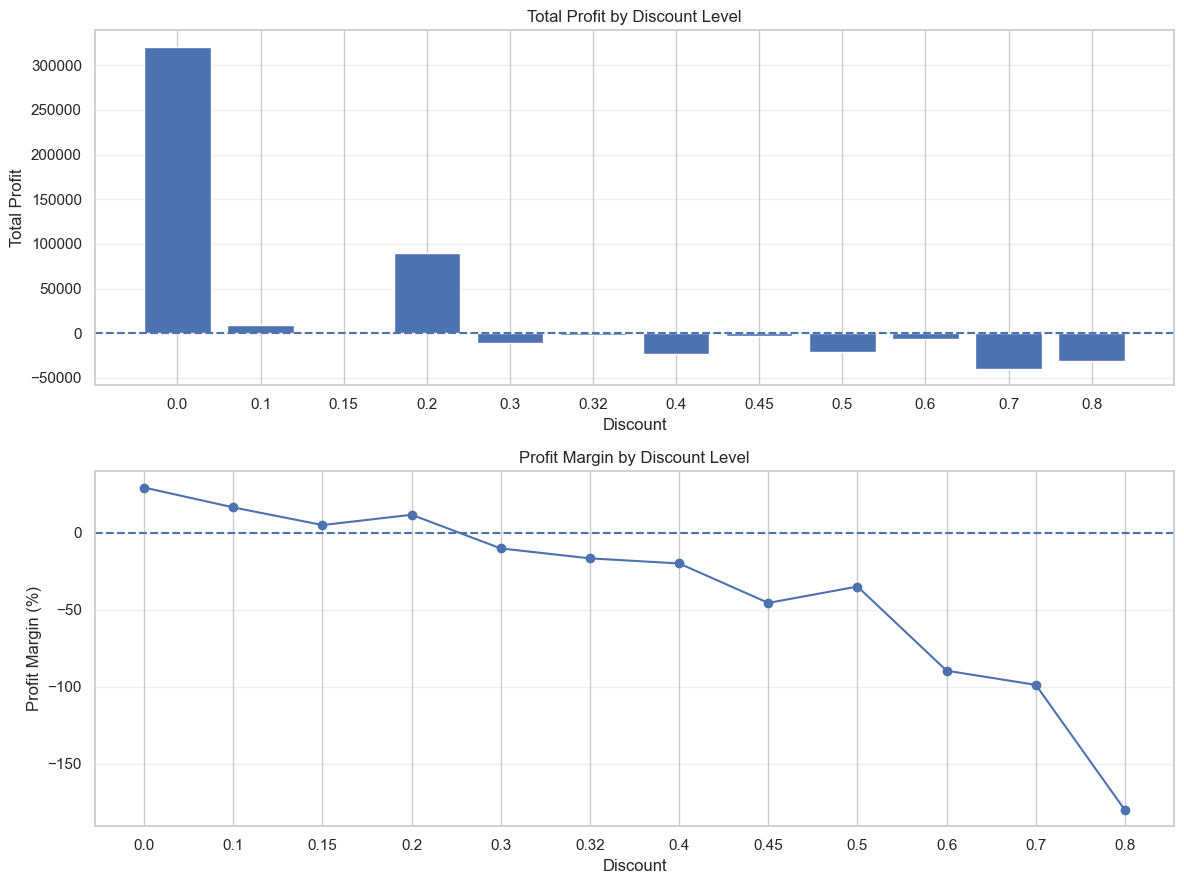

In [40]:
# ==========================================
# DISCOUNT VS PROFIT VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

# Total Profit by Discount
axes[0].bar(
    discount_performance.index.astype(str),
    discount_performance['Total_Profit']
)

axes[0].axhline(y=0, linestyle='--')
axes[0].set_title('Total Profit by Discount Level')
axes[0].set_xlabel('Discount')
axes[0].set_ylabel('Total Profit')
axes[0].grid(axis='y', alpha=0.3)

# Profit Margin by Discount
axes[1].plot(
    discount_performance.index.astype(str),
    discount_performance['Profit_Margin (%)'],
    marker='o'
)

axes[1].axhline(y=0, linestyle='--')
axes[1].set_title('Profit Margin by Discount Level')
axes[1].set_xlabel('Discount')
axes[1].set_ylabel('Profit Margin (%)')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [41]:
# ==========================================
# PRODUCT SUB-CATEGORY PERFORMANCE
# ==========================================

subcategory_performance = (
    df_clean.groupby('Sub-Category')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Quantity=('Quantity', 'sum'),
        Total_Orders=('Order ID', 'nunique'),
        Average_Profit=('Profit', 'mean')
    )
    .sort_values('Total_Profit', ascending=True)
)

# Menghitung Profit Margin
subcategory_performance['Profit_Margin (%)'] = (
    subcategory_performance['Total_Profit'] /
    subcategory_performance['Total_Sales']
) * 100

# Menampilkan hasil
display(subcategory_performance.round(2))

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Average_Profit,Profit_Margin (%)
Sub-Category,,,,,,
Tables,206965.53,-17725.48,1241,307,-55.57,-8.56
Bookcases,114880.00,-3472.56,868,224,-15.23,-3.02
Supplies,46673.54,-1189.10,647,187,-6.26,-2.55
Fasteners,3024.28,949.52,914,215,4.38,31.40
Machines,189238.63,3384.76,440,112,29.43,1.79
Labels,12486.31,5546.25,1400,346,15.24,44.42
Art,27118.79,6527.79,3000,731,8.20,24.07
Envelopes,16476.40,6964.18,906,249,27.42,42.27
Furnishings,91705.16,13059.14,3563,877,13.65,14.24


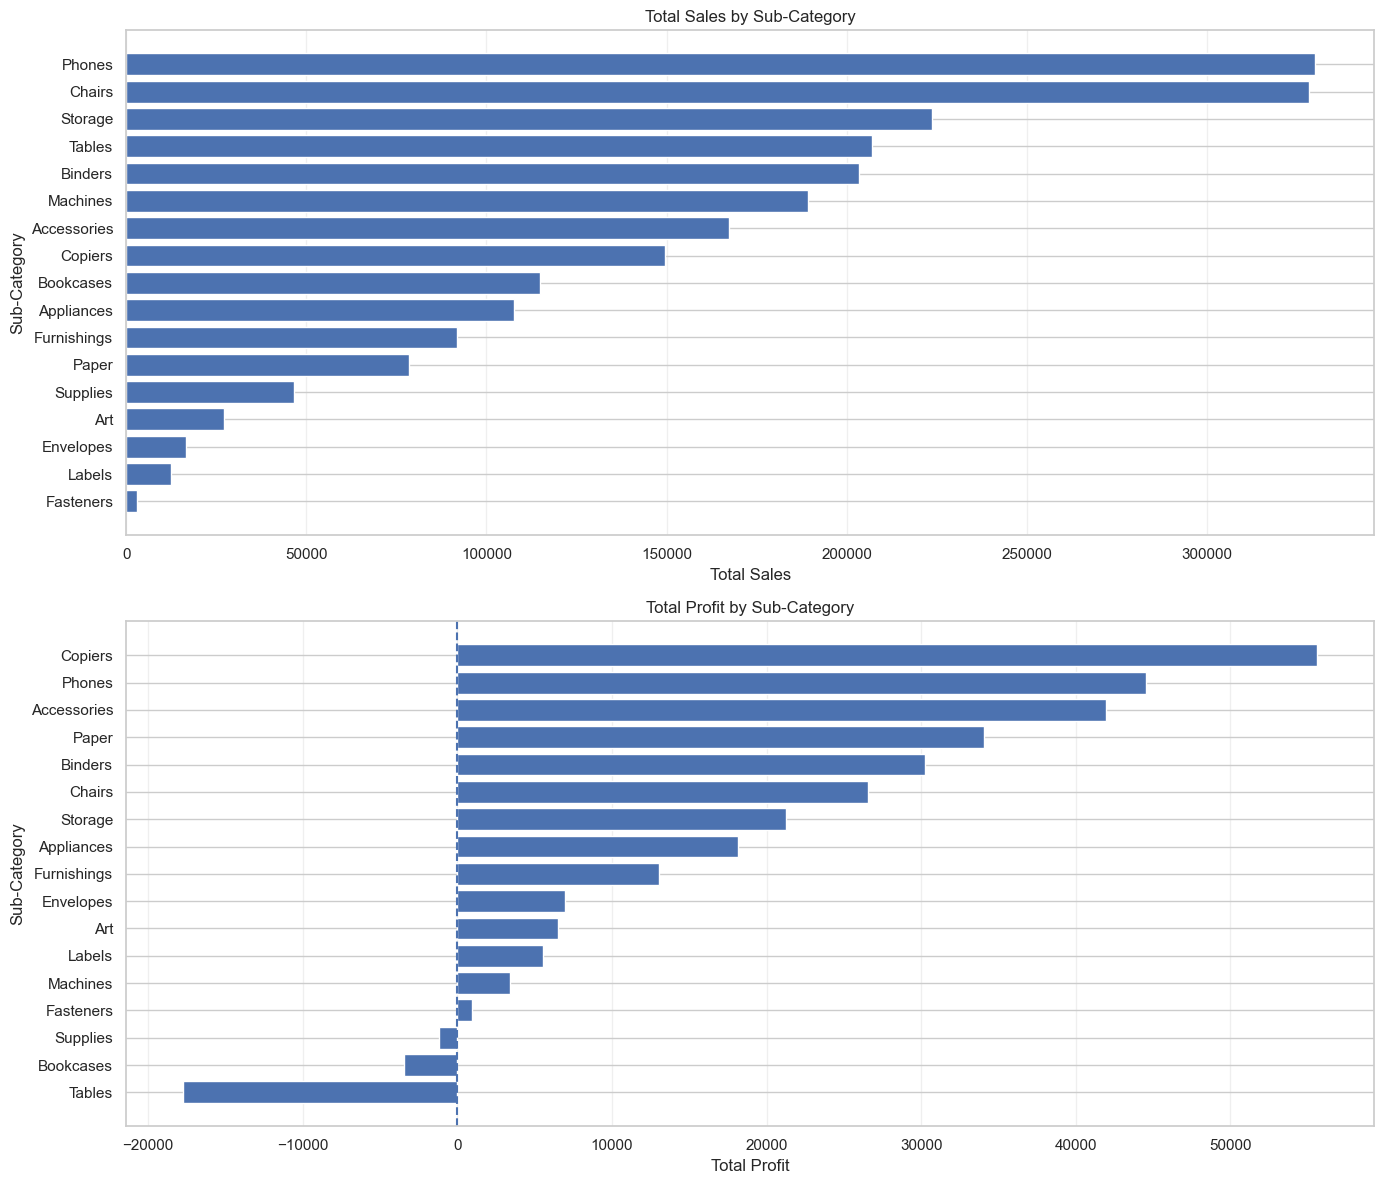

In [42]:
# ==========================================
# SUB-CATEGORY PERFORMANCE VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Total Sales by Sub-Category
sales_sorted = subcategory_performance.sort_values(
    'Total_Sales', ascending=True
)

axes[0].barh(
    sales_sorted.index,
    sales_sorted['Total_Sales']
)

axes[0].set_title('Total Sales by Sub-Category')
axes[0].set_xlabel('Total Sales')
axes[0].set_ylabel('Sub-Category')
axes[0].grid(axis='x', alpha=0.3)


# Total Profit by Sub-Category
profit_sorted = subcategory_performance.sort_values(
    'Total_Profit', ascending=True
)

axes[1].barh(
    profit_sorted.index,
    profit_sorted['Total_Profit']
)

axes[1].axvline(x=0, linestyle='--')
axes[1].set_title('Total Profit by Sub-Category')
axes[1].set_xlabel('Total Profit')
axes[1].set_ylabel('Sub-Category')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [43]:
# ==========================================
# CUSTOMER SEGMENT PERFORMANCE
# ==========================================

segment_performance = (
    df_clean.groupby('Segment')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order ID', 'nunique'),
        Total_Customers=('Customer ID', 'nunique'),
        Total_Quantity=('Quantity', 'sum'),
        Average_Sales=('Sales', 'mean'),
        Average_Profit=('Profit', 'mean')
    )
    .sort_values('Total_Sales', ascending=False)
)

# Menghitung Profit Margin
segment_performance['Profit_Margin (%)'] = (
    segment_performance['Total_Profit'] /
    segment_performance['Total_Sales']
) * 100

display(segment_performance.round(2))

,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Total_Quantity,Average_Sales,Average_Profit,Profit_Margin (%)
Segment,,,,,,,,
Consumer,1161401.34,134119.21,2586,409,19521,223.73,25.84,11.55
Corporate,706146.37,91979.13,1514,236,11608,233.82,30.46,13.03
Home Office,429653.15,60298.68,909,148,6744,240.97,33.82,14.03


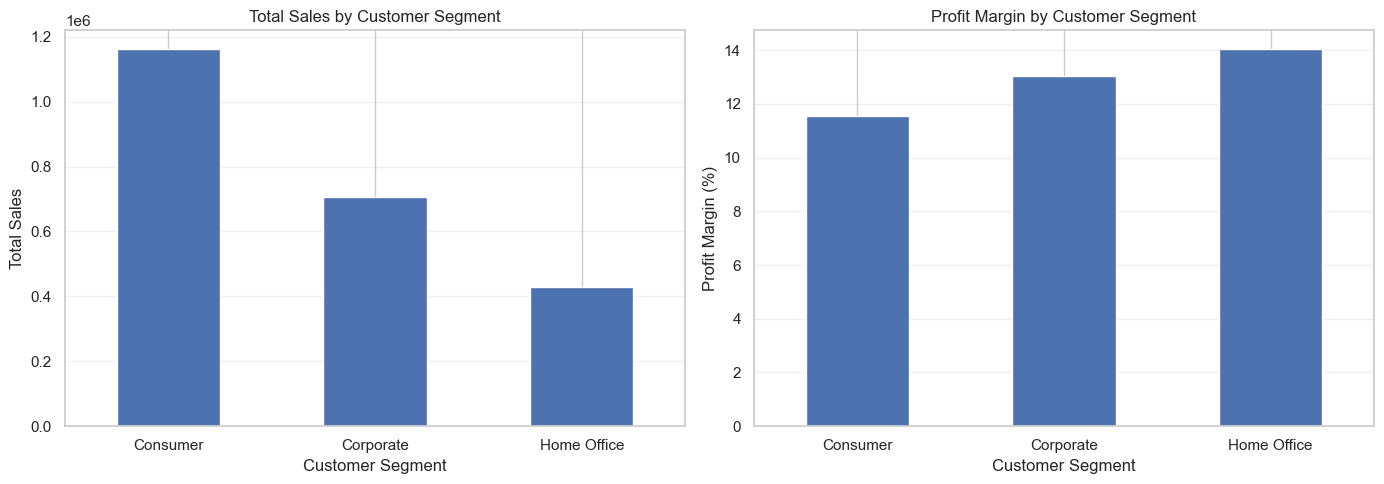

In [44]:
# ==========================================
# CUSTOMER SEGMENT VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Total Sales by Segment
segment_performance['Total_Sales'].plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Total Sales by Customer Segment')
axes[0].set_xlabel('Customer Segment')
axes[0].set_ylabel('Total Sales')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y', alpha=0.3)


# Profit Margin by Segment
segment_performance['Profit_Margin (%)'].plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title('Profit Margin by Customer Segment')
axes[1].set_xlabel('Customer Segment')
axes[1].set_ylabel('Profit Margin (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
# ==========================================
# CUSTOMER ANALYSIS
# CUSTOMER PURCHASE PERFORMANCE
# ==========================================

customer_performance = (
    df_clean.groupby(['Customer ID', 'Customer Name', 'Segment'])
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order ID', 'nunique'),
        Total_Quantity=('Quantity', 'sum')
    )
    .sort_values('Total_Sales', ascending=False)
)

display(customer_performance.head(10).round(2))

,,,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
Customer ID,Customer Name,Segment,,,,
SM-20320,Sean Miller,Home Office,25043.05,-1980.74,5,50
TC-20980,Tamara Chand,Corporate,19052.22,8981.32,5,42
RB-19360,Raymond Buch,Consumer,15117.34,6976.10,6,71
TA-21385,Tom Ashbrook,Home Office,14595.62,4703.79,4,36
AB-10105,Adrian Barton,Consumer,14473.57,5444.81,10,73
KL-16645,Ken Lonsdale,Consumer,14175.23,806.86,12,113
SC-20095,Sanjit Chand,Consumer,14142.33,5757.41,9,87
HL-15040,Hunter Lopez,Consumer,12873.30,5622.43,6,50
SE-20110,Sanjit Engle,Consumer,12209.44,2650.68,11,78


In [46]:
# ==========================================
# CUSTOMER PURCHASE FREQUENCY
# ==========================================

customer_frequency = (
    df_clean.groupby('Customer ID')
    .agg(
        Customer_Name=('Customer Name', 'first'),
        Total_Orders=('Order ID', 'nunique'),
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum')
    )
)

# Distribusi jumlah order per pelanggan
order_frequency_distribution = (
    customer_frequency['Total_Orders']
    .value_counts()
    .sort_index()
)

display(order_frequency_distribution)

Total_Orders
1      12
2      34
3      53
4      96
5     134
6     107
7     116
8      82
9      71
10     39
11     23
12     18
13      7
17      1
Name: count, dtype: int64

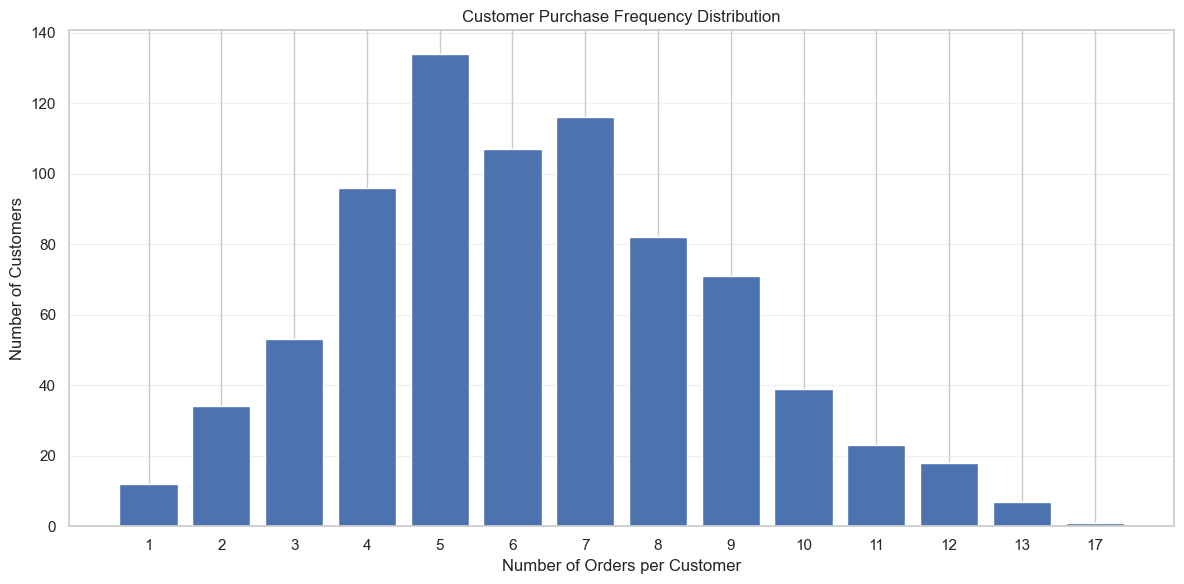

In [47]:
# ==========================================
# CUSTOMER PURCHASE FREQUENCY VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    order_frequency_distribution.index.astype(str),
    order_frequency_distribution.values
)

plt.title('Customer Purchase Frequency Distribution')
plt.xlabel('Number of Orders per Customer')
plt.ylabel('Number of Customers')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [48]:
# ==========================================
# CUSTOMER REVENUE DISTRIBUTION
# ==========================================

# Statistik revenue per pelanggan
customer_revenue_stats = customer_performance['Total_Sales'].describe()

display(customer_revenue_stats.round(2))

count      793.00
mean      2896.85
std       2628.67
min          4.83
25%       1146.05
50%       2256.39
75%       3785.28
max      25043.05
Name: Total_Sales, dtype: float64

In [49]:
# Distribusi pelanggan berdasarkan kelompok revenue

customer_revenue_band = pd.cut(
    customer_performance['Total_Sales'],
    bins=[0, 500, 1000, 2500, 5000, float('inf')],
    labels=[
        '0-500',
        '501-1000',
        '1001-2500',
        '2501-5000',
        'Above 5000'
    ]
)

revenue_band_distribution = (
    customer_revenue_band
    .value_counts()
    .sort_index()
)

display(revenue_band_distribution)

Total_Sales
0-500          73
501-1000       94
1001-2500     270
2501-5000     239
Above 5000    117
Name: count, dtype: int64

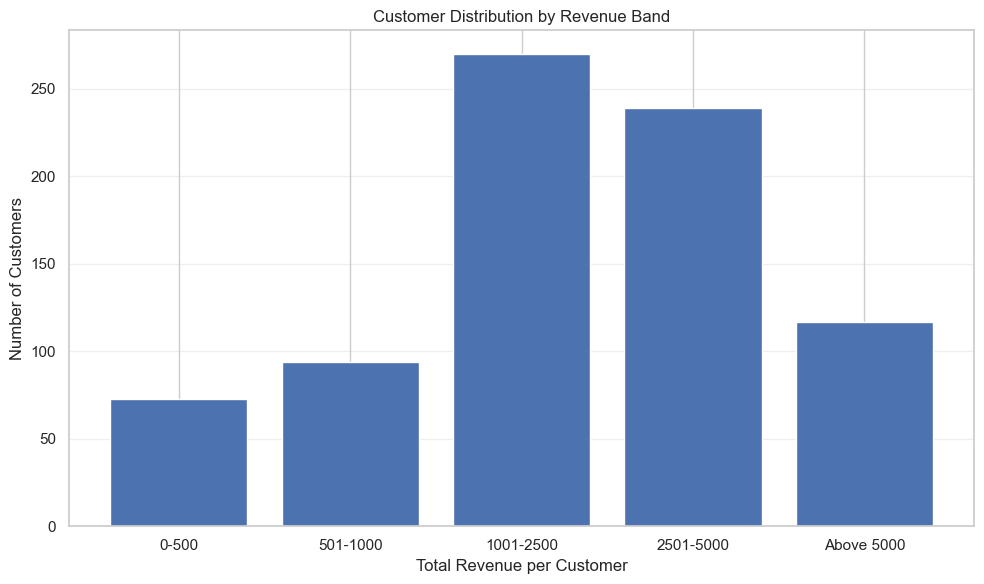

In [50]:
# ==========================================
# CUSTOMER REVENUE BAND VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    revenue_band_distribution.index.astype(str),
    revenue_band_distribution.values
)

plt.title('Customer Distribution by Revenue Band')
plt.xlabel('Total Revenue per Customer')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [51]:
# ==========================================
# CUSTOMER VALUE ANALYSIS
# ==========================================

customer_value = (
    df_clean.groupby(['Customer ID', 'Customer Name', 'Segment'])
    .agg(
        Total_Revenue=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order ID', 'nunique')
    )
)

# Revenue per order
customer_value['Revenue_per_Order'] = (
    customer_value['Total_Revenue'] /
    customer_value['Total_Orders']
)

# Profit margin
customer_value['Profit_Margin (%)'] = (
    customer_value['Total_Profit'] /
    customer_value['Total_Revenue']
) * 100

# Urutkan berdasarkan total profit
customer_value = customer_value.sort_values(
    'Total_Profit',
    ascending=False
)

display(customer_value.head(10).round(2))

,,,Total_Revenue,Total_Profit,Total_Orders,Revenue_per_Order,Profit_Margin (%)
Customer ID,Customer Name,Segment,,,,,
TC-20980,Tamara Chand,Corporate,19052.22,8981.32,5,3810.44,47.14
RB-19360,Raymond Buch,Consumer,15117.34,6976.10,6,2519.56,46.15
SC-20095,Sanjit Chand,Consumer,14142.33,5757.41,9,1571.37,40.71
HL-15040,Hunter Lopez,Consumer,12873.30,5622.43,6,2145.55,43.68
AB-10105,Adrian Barton,Consumer,14473.57,5444.81,10,1447.36,37.62
TA-21385,Tom Ashbrook,Home Office,14595.62,4703.79,4,3648.90,32.23
CM-12385,Christopher Martinez,Consumer,8954.02,3899.89,4,2238.50,43.55
KD-16495,Keith Dawkins,Corporate,8181.26,3038.63,12,681.77,37.14
AR-10540,Andy Reiter,Consumer,6608.45,2884.62,6,1101.41,43.65


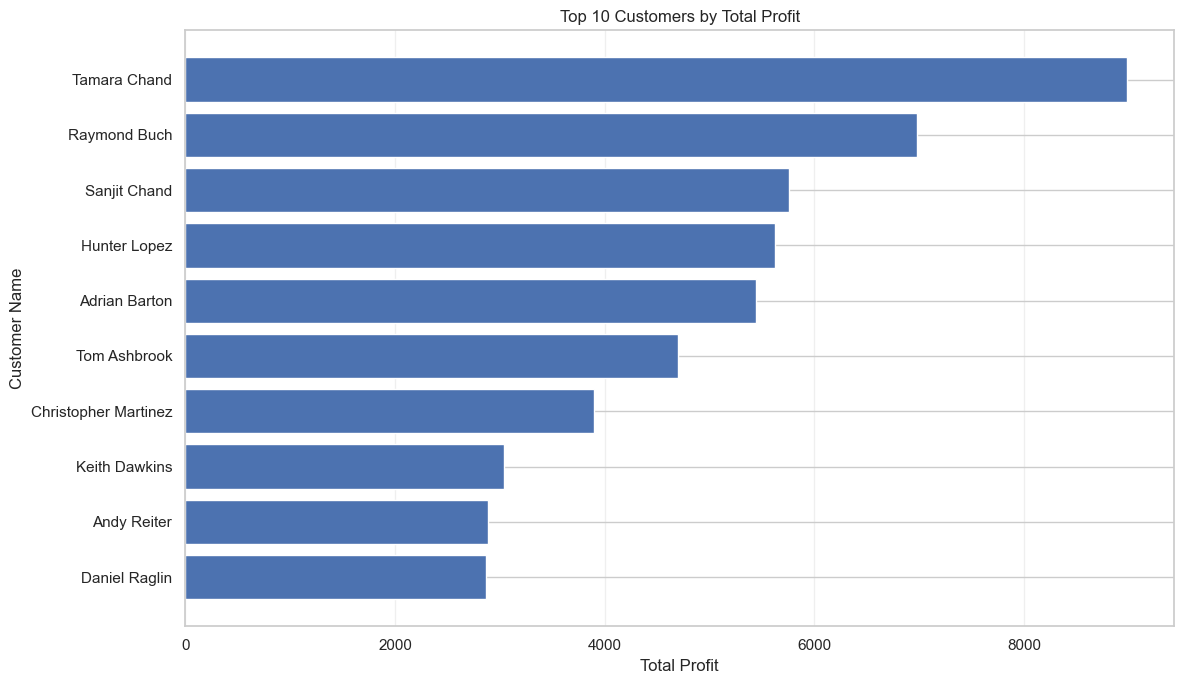

In [52]:
# ==========================================
# TOP 10 CUSTOMERS BY PROFIT
# ==========================================

import matplotlib.pyplot as plt

top_10_profit_customers = (
    customer_value
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_profit_customers['Customer Name'],
    top_10_profit_customers['Total_Profit']
)

plt.title('Top 10 Customers by Total Profit')
plt.xlabel('Total Profit')
plt.ylabel('Customer Name')

plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [53]:
# ==========================================
# GEOGRAPHIC ANALYSIS
# SALES AND PROFIT BY STATE
# ==========================================

state_performance = (
    df_clean.groupby('State')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order ID', 'nunique'),
        Total_Customers=('Customer ID', 'nunique'),
        Total_Quantity=('Quantity', 'sum')
    )
)

state_performance['Profit_Margin (%)'] = (
    state_performance['Total_Profit'] /
    state_performance['Total_Sales']
) * 100

# Top 10 states berdasarkan revenue
top_10_states = state_performance.sort_values(
    'Total_Sales',
    ascending=False
).head(10)

display(top_10_states.round(2))

,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Total_Quantity,Profit_Margin (%)
State,,,,,,
California,457687.63,76381.39,1021,577,7667,16.69
New York,310876.27,74038.55,562,415,4224,23.82
Texas,170188.05,-25729.36,487,370,3724,-15.12
Washington,138641.27,33402.65,256,224,1883,24.09
Pennsylvania,116511.91,-15559.96,288,257,2153,-13.35
Florida,89473.71,-3399.30,200,181,1379,-3.80
Illinois,80166.10,-12607.89,276,237,1845,-15.73
Ohio,78258.14,-16971.38,236,202,1759,-21.69
Michigan,76269.61,24463.19,117,106,946,32.07


In [54]:
# Top 10 states dengan profit terendah

bottom_10_profit_states = state_performance.sort_values(
    'Total_Profit',
    ascending=True
).head(10)

display(bottom_10_profit_states.round(2))

,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Total_Quantity,Profit_Margin (%)
State,,,,,,
Texas,170188.05,-25729.36,487,370,3724,-15.12
Ohio,78258.14,-16971.38,236,202,1759,-21.69
Pennsylvania,116511.91,-15559.96,288,257,2153,-13.35
Illinois,80166.10,-12607.89,276,237,1845,-15.73
North Carolina,55603.16,-7490.91,136,122,983,-13.47
Colorado,32108.12,-6527.86,79,75,693,-20.33
Tennessee,30661.87,-5341.69,91,84,681,-17.42
Arizona,35282.00,-3427.92,108,100,862,-9.72
Florida,89473.71,-3399.30,200,181,1379,-3.80


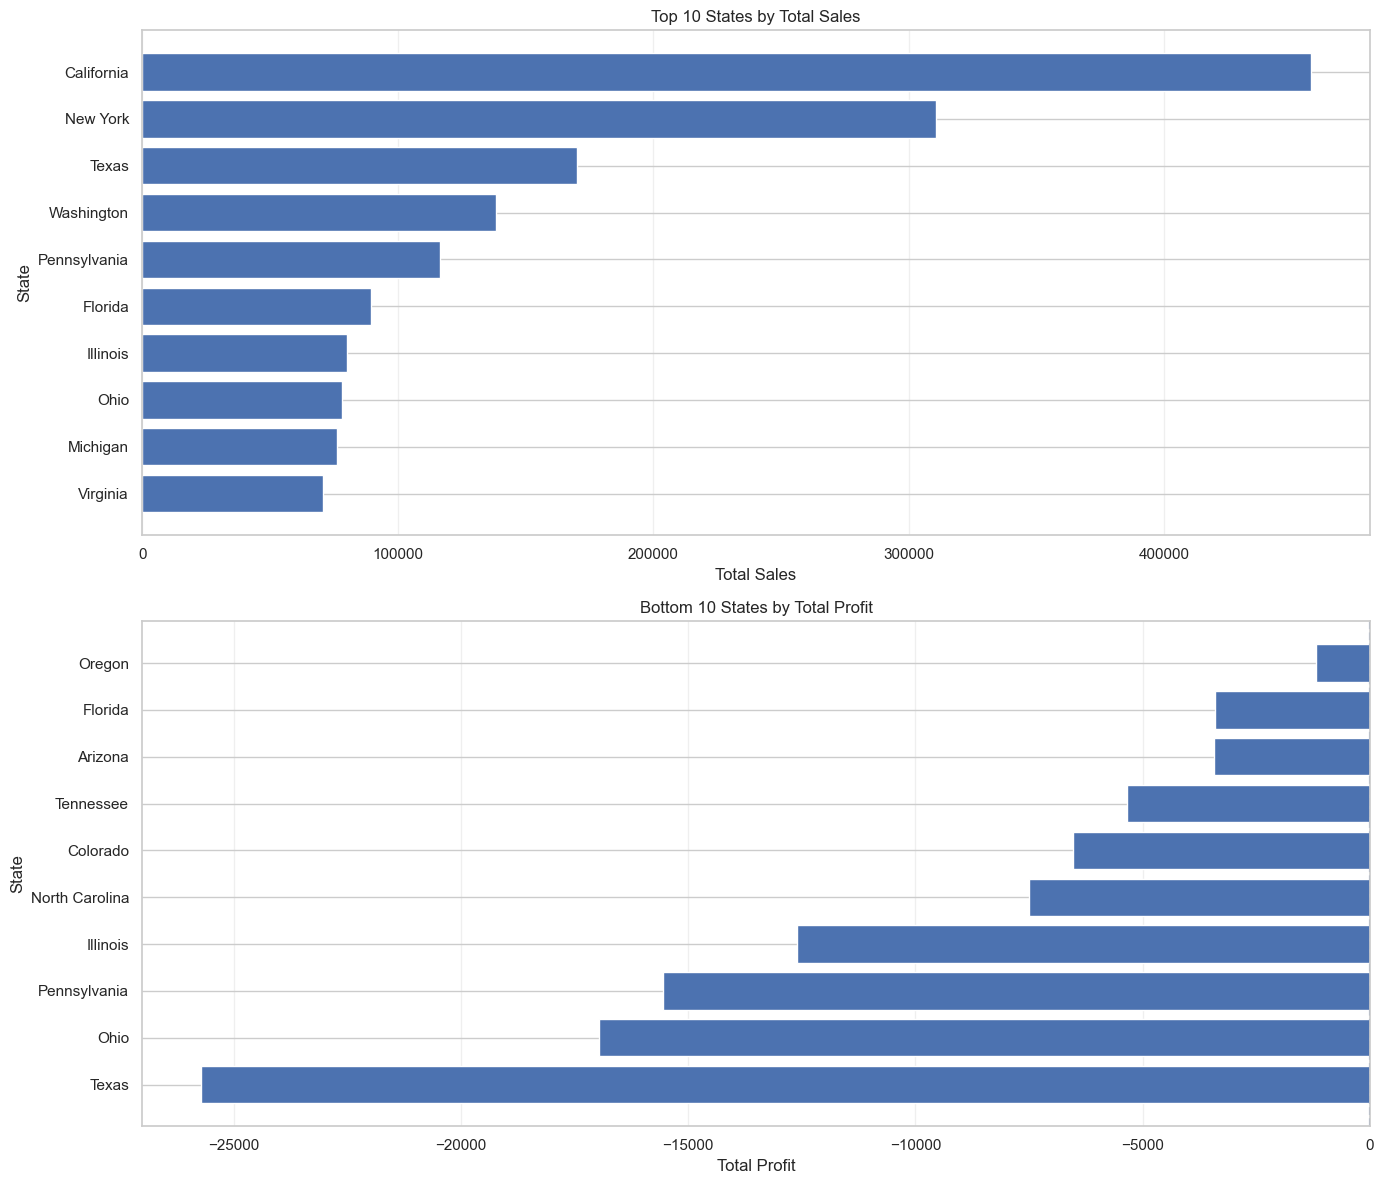

In [55]:
# ==========================================
# GEOGRAPHIC VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Top 10 States by Revenue
top_10_states_sorted = top_10_states.sort_values(
    'Total_Sales',
    ascending=True
)

axes[0].barh(
    top_10_states_sorted.index,
    top_10_states_sorted['Total_Sales']
)

axes[0].set_title('Top 10 States by Total Sales')
axes[0].set_xlabel('Total Sales')
axes[0].set_ylabel('State')
axes[0].grid(axis='x', alpha=0.3)


# Bottom 10 States by Profit
bottom_10_sorted = bottom_10_profit_states.sort_values(
    'Total_Profit',
    ascending=True
)

axes[1].barh(
    bottom_10_sorted.index,
    bottom_10_sorted['Total_Profit']
)

axes[1].axvline(x=0, linestyle='--')
axes[1].set_title('Bottom 10 States by Total Profit')
axes[1].set_xlabel('Total Profit')
axes[1].set_ylabel('State')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [56]:
# ==========================================
# SALES AND PROFIT BY REGION
# ==========================================

region_geographic = (
    df_clean.groupby('Region')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order ID', 'nunique'),
        Total_Customers=('Customer ID', 'nunique'),
        Total_Quantity=('Quantity', 'sum')
    )
    .sort_values('Total_Sales', ascending=False)
)

region_geographic['Profit_Margin (%)'] = (
    region_geographic['Total_Profit'] /
    region_geographic['Total_Sales']
) * 100

display(region_geographic.round(2))

,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Total_Quantity,Profit_Margin (%)
Region,,,,,,
West,725457.82,108418.45,1611,686,12266,14.94
East,678781.24,91522.78,1401,674,10618,13.48
Central,501239.89,39706.36,1175,629,8780,7.92
South,391721.90,46749.43,822,512,6209,11.93


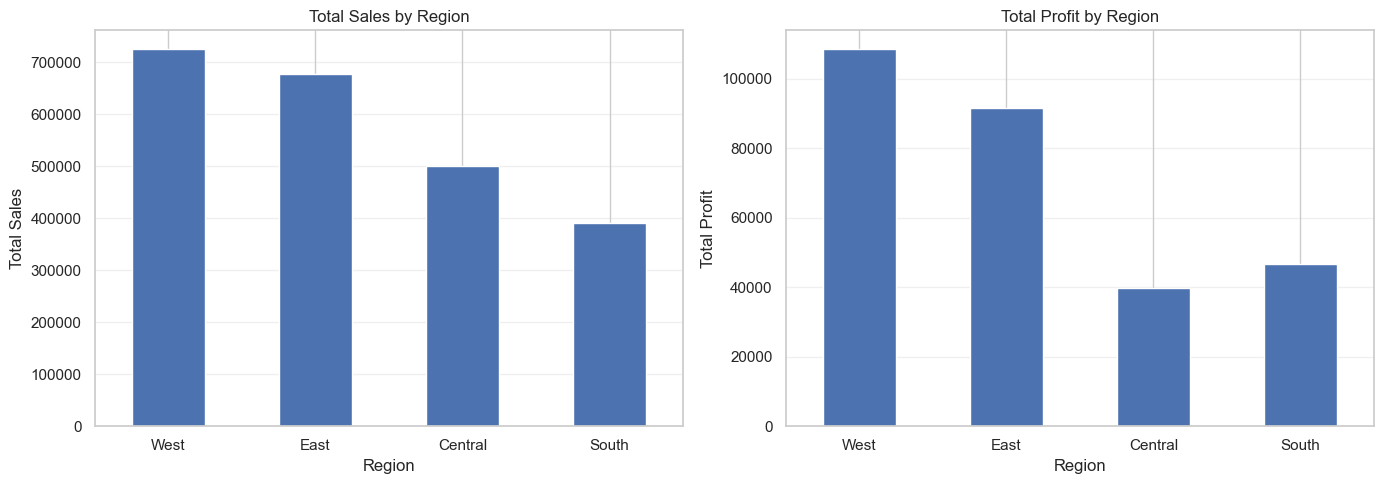

In [57]:
# ==========================================
# REGION PERFORMANCE VISUALIZATION
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Revenue by Region
region_geographic['Total_Sales'].plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Total Sales by Region')
axes[0].set_xlabel('Region')
axes[0].set_ylabel('Total Sales')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y', alpha=0.3)

# Profit by Region
region_geographic['Total_Profit'].plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title('Total Profit by Region')
axes[1].set_xlabel('Region')
axes[1].set_ylabel('Total Profit')
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [58]:
# ==========================================
# SHIPPING AND DELIVERY ANALYSIS
# SHIPPING MODE PERFORMANCE
# ==========================================

shipping_performance = (
    df_clean.groupby('Ship Mode')
    .agg(
        Total_Order_Lines=('Order ID', 'count'),
        Total_Orders=('Order ID', 'nunique'),
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Quantity=('Quantity', 'sum')
    )
    .sort_values('Total_Orders', ascending=False)
)

shipping_performance['Profit_Margin (%)'] = (
    shipping_performance['Total_Profit'] /
    shipping_performance['Total_Sales']
) * 100

display(shipping_performance.round(2))

,Total_Order_Lines,Total_Orders,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin (%)
Ship Mode,,,,,,
Standard Class,5968,2994,1358215.74,164088.79,22797,12.08
Second Class,1945,964,459193.57,57446.64,7423,12.51
First Class,1538,787,351428.42,48969.84,5693,13.93
Same Day,543,264,128363.12,15891.76,1960,12.38


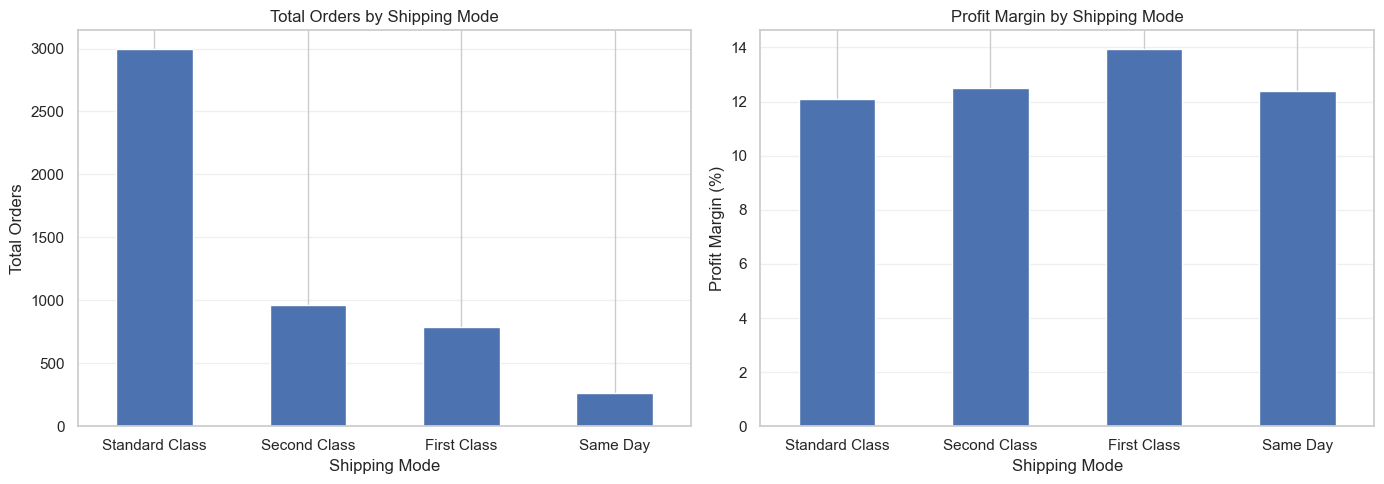

In [59]:
# ==========================================
# SHIPPING MODE VISUALIZATION
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Total Orders by Ship Mode
shipping_performance['Total_Orders'].plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Total Orders by Shipping Mode')
axes[0].set_xlabel('Shipping Mode')
axes[0].set_ylabel('Total Orders')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y', alpha=0.3)

# Profit Margin by Ship Mode
shipping_performance['Profit_Margin (%)'].plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title('Profit Margin by Shipping Mode')
axes[1].set_xlabel('Shipping Mode')
axes[1].set_ylabel('Profit Margin (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [60]:
# ==========================================
# DELIVERY DURATION ANALYSIS
# ==========================================

# Menghitung durasi antara Order Date dan Ship Date
df_clean['Shipping_Duration'] = (
    df_clean['Ship Date'] - df_clean['Order Date']
).dt.days

# Statistik durasi pengiriman
delivery_stats = df_clean['Shipping_Duration'].describe()

display(delivery_stats)

count    9994.000000
mean        3.958175
std         1.747567
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Shipping_Duration, dtype: float64

In [61]:
# Rata-rata durasi pengiriman berdasarkan Ship Mode

delivery_by_shipmode = (
    df_clean.groupby('Ship Mode')
    .agg(
        Average_Delivery_Days=('Shipping_Duration', 'mean'),
        Median_Delivery_Days=('Shipping_Duration', 'median'),
        Minimum_Delivery_Days=('Shipping_Duration', 'min'),
        Maximum_Delivery_Days=('Shipping_Duration', 'max'),
        Total_Orders=('Order ID', 'nunique')
    )
    .sort_values('Average_Delivery_Days')
)

display(delivery_by_shipmode.round(2))

,Average_Delivery_Days,Median_Delivery_Days,Minimum_Delivery_Days,Maximum_Delivery_Days,Total_Orders
Ship Mode,,,,,
Same Day,0.04,0.0,0,1,264
First Class,2.18,2.0,1,4,787
Second Class,3.24,3.0,1,5,964
Standard Class,5.01,5.0,3,7,2994


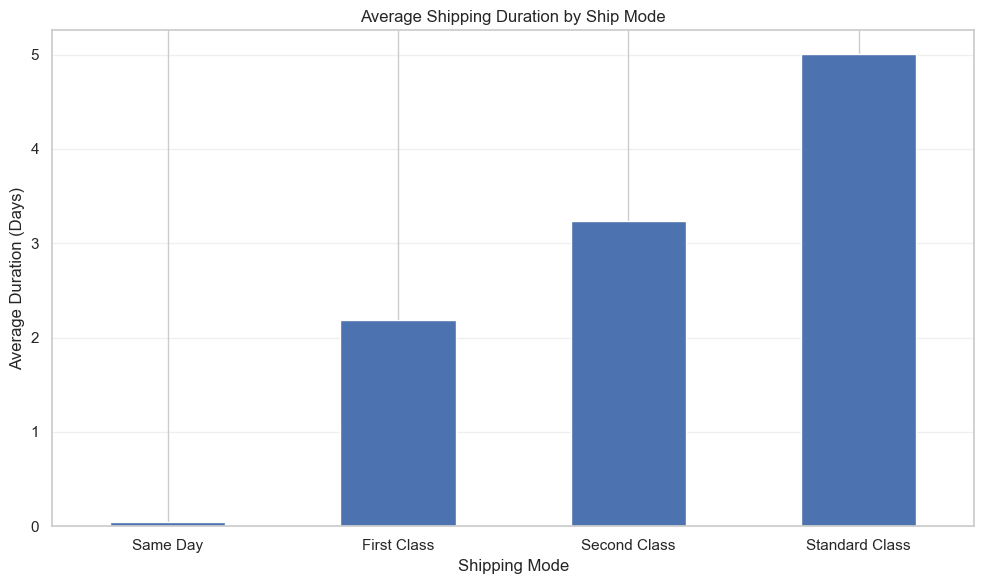

In [62]:
# ==========================================
# DELIVERY DURATION VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

delivery_by_shipmode['Average_Delivery_Days'].plot(
    kind='bar'
)

plt.title('Average Shipping Duration by Ship Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Average Duration (Days)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

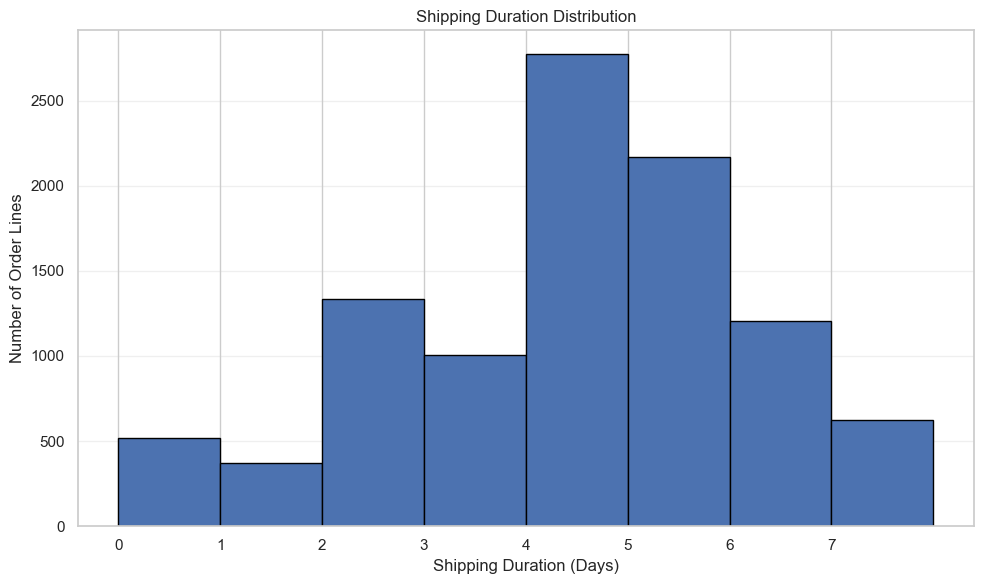

In [63]:
# Distribution of Shipping Duration

plt.figure(figsize=(10, 6))

plt.hist(
    df_clean['Shipping_Duration'],
    bins=range(0, 9),
    edgecolor='black'
)

plt.title('Shipping Duration Distribution')
plt.xlabel('Shipping Duration (Days)')
plt.ylabel('Number of Order Lines')
plt.xticks(range(0, 8))
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [64]:
# ==========================================
# SHIPPING DURATION VS PROFIT
# ==========================================

delivery_profit_analysis = (
    df_clean.groupby('Shipping_Duration')
    .agg(
        Total_Orders=('Order ID', 'nunique'),
        Total_Sales=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Average_Profit=('Profit', 'mean'),
        Total_Quantity=('Quantity', 'sum')
    )
    .sort_index()
)

delivery_profit_analysis['Profit_Margin (%)'] = (
    delivery_profit_analysis['Total_Profit'] /
    delivery_profit_analysis['Total_Sales']
) * 100

display(delivery_profit_analysis.round(2))

,Total_Orders,Total_Sales,Total_Profit,Average_Profit,Total_Quantity,Profit_Margin (%)
Shipping_Duration,,,,,,
0,252,124907.69,15385.97,29.65,1864,12.32
1,182,67975.33,7541.23,20.44,1384,11.09
2,675,368465.83,53118.11,39.82,4989,14.42
3,509,204659.60,26875.92,26.74,3811,13.13
4,1403,631847.01,71134.77,25.64,10665,11.26
5,1084,494357.08,58733.20,27.08,8205,11.88
6,596,240290.57,33275.97,27.66,4546,13.85
7,308,164697.75,20331.85,32.74,2409,12.34


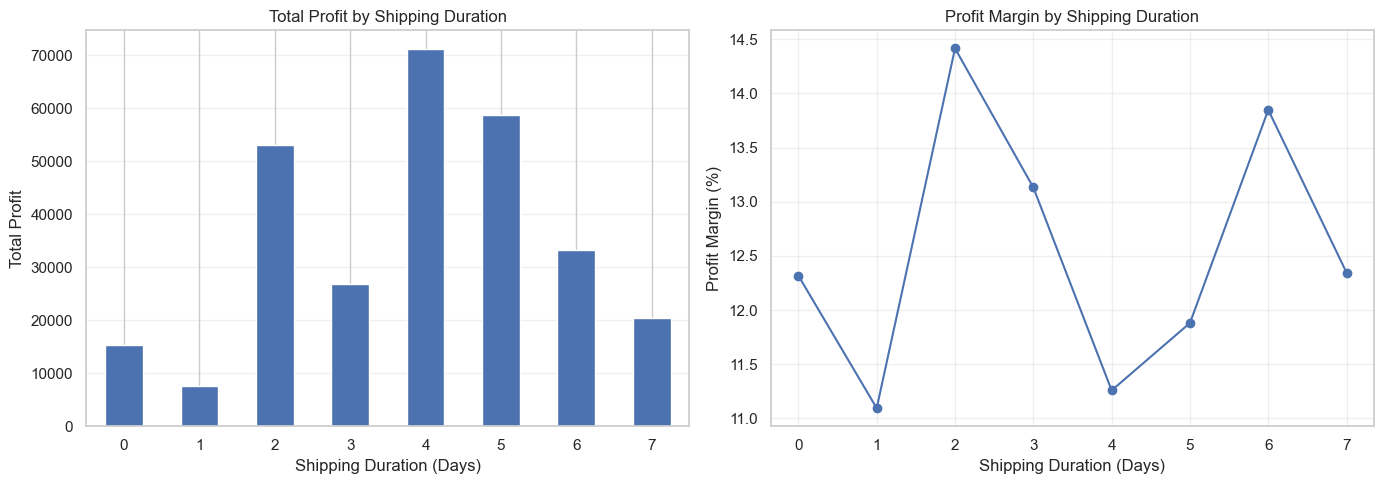

In [65]:
# ==========================================
# SHIPPING DURATION VS PROFIT VISUALIZATION
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Total Profit by Shipping Duration
delivery_profit_analysis['Total_Profit'].plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Total Profit by Shipping Duration')
axes[0].set_xlabel('Shipping Duration (Days)')
axes[0].set_ylabel('Total Profit')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y', alpha=0.3)

# Profit Margin by Shipping Duration
delivery_profit_analysis['Profit_Margin (%)'].plot(
    kind='line',
    marker='o',
    ax=axes[1]
)

axes[1].set_title('Profit Margin by Shipping Duration')
axes[1].set_xlabel('Shipping Duration (Days)')
axes[1].set_ylabel('Profit Margin (%)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# BUSINESS INSIGHTS

## Overall Business Performance

In [66]:
# ==========================================
# OVERALL BUSINESS PERFORMANCE
# ==========================================

total_sales = df_clean['Sales'].sum()
total_profit = df_clean['Profit'].sum()
total_orders = df_clean['Order ID'].nunique()
total_customers = df_clean['Customer ID'].nunique()
total_products = df_clean['Product ID'].nunique()
total_quantity = df_clean['Quantity'].sum()

overall_profit_margin = (total_profit / total_sales) * 100
average_order_value = total_sales / total_orders

print("===== OVERALL BUSINESS PERFORMANCE =====")
print(f"Total Sales       : ${total_sales:,.2f}")
print(f"Total Profit      : ${total_profit:,.2f}")
print(f"Total Orders      : {total_orders:,}")
print(f"Total Customers   : {total_customers:,}")
print(f"Total Products    : {total_products:,}")
print(f"Total Quantity    : {total_quantity:,}")
print(f"Profit Margin     : {overall_profit_margin:.2f}%")
print(f"Average Order Value: ${average_order_value:,.2f}")

===== OVERALL BUSINESS PERFORMANCE =====
Total Sales       : $2,297,200.86
Total Profit      : $286,397.02
Total Orders      : 5,009
Total Customers   : 793
Total Products    : 1,862
Total Quantity    : 37,873
Profit Margin     : 12.47%
Average Order Value: $458.61


## Sales and profitability Insights

In [67]:
# ==========================================
# SALES AND PROFITABILITY INSIGHTS
# ==========================================

# Overall sales and profit by category
category_insights = category_performance[
    ['Total_Sales', 'Total_Profit', 'Profit_Margin (%)']
].sort_values('Total_Sales', ascending=False)

# Overall sales and profit by region
region_insights = region_performance[
    ['Total_Sales', 'Total_Profit', 'Profit_Margin (%)']
].sort_values('Total_Sales', ascending=False)

print("===== SALES & PROFITABILITY BY CATEGORY =====")
display(category_insights.round(2))

print("===== SALES & PROFITABILITY BY REGION =====")
display(region_insights.round(2))

print("===== YEARLY SALES & PROFIT =====")
display(yearly_performance[
    ['Total_Sales', 'Total_Profit', 'Profit_Margin (%)']
].round(2))

===== SALES & PROFITABILITY BY CATEGORY =====


,Total_Sales,Total_Profit,Profit_Margin (%)
Category,,,
Technology,836154.03,145454.95,17.40
Furniture,741999.80,18451.27,2.49
Office Supplies,719047.03,122490.80,17.04


===== SALES & PROFITABILITY BY REGION =====


,Total_Sales,Total_Profit,Profit_Margin (%)
Region,,,
West,725457.82,108418.45,14.94
East,678781.24,91522.78,13.48
Central,501239.89,39706.36,7.92
South,391721.90,46749.43,11.93


===== YEARLY SALES & PROFIT =====


,Total_Sales,Total_Profit,Profit_Margin (%)
Order Date,,,
2014,484247.50,49543.97,10.23
2015,470532.51,61618.60,13.10
2016,609205.60,81795.17,13.43
2017,733215.26,93439.27,12.74


### Key Business Findings

1. Technology is the strongest product category in terms of revenue and total profit.
2. Furniture has relatively high sales but the lowest profit margin, indicating potential profitability issues.
3. West is the strongest region, while Central has the lowest profit margin.
4. Revenue and profit generally increased from 2014 to 2017, although revenue declined slightly in 2015.
5. Profit margin peaked in 2016 before decreasing slightly in 2017.

### Business Recommendations

1. Maintain the performance of Technology and Office Supplies.
2. Review Furniture pricing, discount strategies, and product costs.
3. Investigate profitability issues in the Central region.
4. Maintain revenue growth while monitoring profit margin.
5. Evaluate product and regional performance regularly to identify opportunities for improvement.

## Product Performance Insights

In [68]:
# ==========================================
# PRODUCT PERFORMANCE INSIGHTS
# ==========================================

print("===== TOP 5 SUB-CATEGORIES BY SALES =====")

display(
    subcategory_performance
    .sort_values('Total_Sales', ascending=False)
    [['Total_Sales', 'Total_Profit', 'Profit_Margin (%)']]
    .head(5)
    .round(2)
)

print("===== TOP 5 SUB-CATEGORIES BY PROFIT =====")

display(
    subcategory_performance
    .sort_values('Total_Profit', ascending=False)
    [['Total_Sales', 'Total_Profit', 'Profit_Margin (%)']]
    .head(5)
    .round(2)
)

print("===== BOTTOM 5 SUB-CATEGORIES BY PROFIT =====")

display(
    subcategory_performance
    .sort_values('Total_Profit', ascending=True)
    [['Total_Sales', 'Total_Profit', 'Profit_Margin (%)']]
    .head(5)
    .round(2)
)

===== TOP 5 SUB-CATEGORIES BY SALES =====


,Total_Sales,Total_Profit,Profit_Margin (%)
Sub-Category,,,
Phones,330007.05,44515.73,13.49
Chairs,328449.10,26590.17,8.10
Storage,223843.61,21278.83,9.51
Tables,206965.53,-17725.48,-8.56
Binders,203412.73,30221.76,14.86


===== TOP 5 SUB-CATEGORIES BY PROFIT =====


,Total_Sales,Total_Profit,Profit_Margin (%)
Sub-Category,,,
Copiers,149528.03,55617.82,37.20
Phones,330007.05,44515.73,13.49
Accessories,167380.32,41936.64,25.05
Paper,78479.21,34053.57,43.39
Binders,203412.73,30221.76,14.86


===== BOTTOM 5 SUB-CATEGORIES BY PROFIT =====


,Total_Sales,Total_Profit,Profit_Margin (%)
Sub-Category,,,
Tables,206965.53,-17725.48,-8.56
Bookcases,114880.00,-3472.56,-3.02
Supplies,46673.54,-1189.10,-2.55
Fasteners,3024.28,949.52,31.40
Machines,189238.63,3384.76,1.79


### Key Business Findings

1. Phones generates the highest revenue among all product sub-categories.
2. Copiers generates the highest total profit, while Paper has the highest profit margin among the top five profitable sub-categories.
3. Tables generates substantial revenue but records the largest total loss.
4. Bookcases and Supplies also record negative total profit.
5. High sales revenue does not necessarily translate into high profitability.

### Business Recommendations

1. Maintain the sales performance of Phones and other high-revenue products.
2. Focus on profitable sub-categories such as Copiers, Accessories, and Paper.
3. Review pricing, discount policies, and product costs for Tables.
4. Investigate the profitability of Bookcases and Supplies.
5. Monitor both revenue and profit margin when evaluating product performance.

## Customer Performance Insights

In [72]:
# ==========================================
# CUSTOMER PERFORMANCE INSIGHTS
# ==========================================

# Membuat ringkasan performa setiap pelanggan
customer_insights = (
    df_clean.groupby('Customer ID')
    .agg(
        Customer_Name=('Customer Name', 'first'),
        Segment=('Segment', 'first'),
        Total_Revenue=('Sales', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Total_Orders=('Order ID', 'nunique'),
        Total_Quantity=('Quantity', 'sum')
    )
)

# Menghitung profit margin
customer_insights['Profit_Margin (%)'] = (
    customer_insights['Total_Profit'] /
    customer_insights['Total_Revenue']
) * 100

print("Customer insights dataset created!")
print("Total customers:", len(customer_insights))

Customer insights dataset created!
Total customers: 793


## Customer Performance Analysis

In [73]:
# ==========================================
# CUSTOMER PERFORMANCE ANALYSIS
# ==========================================

print("===== CUSTOMER SEGMENT PERFORMANCE =====")

display(
    segment_performance[
        ['Total_Sales', 'Total_Profit',
         'Total_Orders', 'Total_Customers',
         'Profit_Margin (%)']
    ].round(2)
)

print("===== TOP 5 CUSTOMERS BY REVENUE =====")

display(
    customer_insights
    .sort_values('Total_Revenue', ascending=False)
    [['Customer_Name', 'Segment', 'Total_Revenue',
      'Total_Profit', 'Total_Orders']]
    .head(5)
    .round(2)
)

print("===== TOP 5 CUSTOMERS BY PROFIT =====")

display(
    customer_insights
    .sort_values('Total_Profit', ascending=False)
    [['Customer_Name', 'Segment', 'Total_Revenue',
      'Total_Profit', 'Total_Orders', 'Profit_Margin (%)']]
    .head(5)
    .round(2)
)

===== CUSTOMER SEGMENT PERFORMANCE =====


,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Profit_Margin (%)
Segment,,,,,
Consumer,1161401.34,134119.21,2586,409,11.55
Corporate,706146.37,91979.13,1514,236,13.03
Home Office,429653.15,60298.68,909,148,14.03


===== TOP 5 CUSTOMERS BY REVENUE =====


,Customer_Name,Segment,Total_Revenue,Total_Profit,Total_Orders
Customer ID,,,,,
SM-20320,Sean Miller,Home Office,25043.05,-1980.74,5
TC-20980,Tamara Chand,Corporate,19052.22,8981.32,5
RB-19360,Raymond Buch,Consumer,15117.34,6976.10,6
TA-21385,Tom Ashbrook,Home Office,14595.62,4703.79,4
AB-10105,Adrian Barton,Consumer,14473.57,5444.81,10


===== TOP 5 CUSTOMERS BY PROFIT =====


,Customer_Name,Segment,Total_Revenue,Total_Profit,Total_Orders,Profit_Margin (%)
Customer ID,,,,,,
TC-20980,Tamara Chand,Corporate,19052.22,8981.32,5,47.14
RB-19360,Raymond Buch,Consumer,15117.34,6976.10,6,46.15
SC-20095,Sanjit Chand,Consumer,14142.33,5757.41,9,40.71
HL-15040,Hunter Lopez,Consumer,12873.30,5622.43,6,43.68
AB-10105,Adrian Barton,Consumer,14473.57,5444.81,10,37.62


### Key Business Findings

1. Consumer contributes the highest revenue and total profit among customer segments.
2. Home Office has the highest profit margin at 14.03%.
3. Sean Miller is the highest-revenue customer but generates a negative total profit.
4. Tamara Chand is the most profitable customer, generating $8,981.32 in profit.
5. Customer revenue contribution does not necessarily reflect customer profitability.

### Business Recommendations

1. Maintain customer engagement strategies for the Consumer segment.
2. Develop growth opportunities in the Home Office segment.
3. Review pricing and discount strategies for high-revenue but unprofitable customers.
4. Identify purchasing patterns of highly profitable customers.
5. Develop customer retention strategies based on customer profitability, not revenue alone.

## Customer Purchase Freuency

In [75]:
# ==========================================
# CUSTOMER PURCHASE FREQUENCY
# ==========================================

# Menghitung jumlah pesanan unik setiap pelanggan
customer_order_frequency = (
    df_clean.groupby('Customer ID')['Order ID']
    .nunique()
)

# Menghitung distribusi frekuensi pembelian
customer_frequency_distribution = (
    customer_order_frequency
    .value_counts()
    .sort_index()
)

# Menghitung one-time dan repeat customers
one_time_customers = (
    customer_order_frequency == 1
).sum()

repeat_customers = (
    customer_order_frequency > 1
).sum()

total_customers = len(customer_order_frequency)

# Menampilkan hasil
print("===== CUSTOMER PURCHASE FREQUENCY =====")
display(customer_frequency_distribution)

print("\n===== CUSTOMER RETENTION OVERVIEW =====")
print(f"One-time Customers : {one_time_customers}")
print(f"Repeat Customers   : {repeat_customers}")
print(f"Total Customers    : {total_customers}")

print(
    f"One-time Customer Rate: "
    f"{one_time_customers / total_customers * 100:.2f}%"
)

print(
    f"Repeat Customer Rate: "
    f"{repeat_customers / total_customers * 100:.2f}%"
)

===== CUSTOMER PURCHASE FREQUENCY =====


Order ID
1      12
2      34
3      53
4      96
5     134
6     107
7     116
8      82
9      71
10     39
11     23
12     18
13      7
17      1
Name: count, dtype: int64


===== CUSTOMER RETENTION OVERVIEW =====
One-time Customers : 12
Repeat Customers   : 781
Total Customers    : 793
One-time Customer Rate: 1.51%
Repeat Customer Rate: 98.49%


### Key Business Findings

1. 781 out of 793 customers are repeat customers, representing 98.49%.
2. Only 12 customers (1.51%) made a single purchase.
3. The most common purchase frequency is five orders per customer, with 134 customers.

### Business Recommendations

1. Maintain relationships with existing repeat customers.
2. Identify purchasing patterns of customers with high order frequency.
3. Develop campaigns to encourage one-time customers to make repeat purchases.
4. Monitor customer retention trends over time.

## Geographic Performance Insights

In [77]:
# ==========================================
# GEOGRAPHIC PERFORMANCE INSIGHTS
# ==========================================

print("===== TOP 5 STATES BY SALES =====")

display(
    state_performance
    .sort_values('Total_Sales', ascending=False)
    [['Total_Sales', 'Total_Profit', 'Profit_Margin (%)']]
    .head(5)
    .round(2)
)

print("===== TOP 5 STATES BY PROFIT =====")

display(
    state_performance
    .sort_values('Total_Profit', ascending=False)
    [['Total_Sales', 'Total_Profit', 'Profit_Margin (%)']]
    .head(5)
    .round(2)
)

print("===== BOTTOM 5 STATES BY PROFIT =====")

display(
    state_performance
    .sort_values('Total_Profit', ascending=True)
    [['Total_Sales', 'Total_Profit', 'Profit_Margin (%)']]
    .head(5)
    .round(2)
)

===== TOP 5 STATES BY SALES =====


,Total_Sales,Total_Profit,Profit_Margin (%)
State,,,
California,457687.63,76381.39,16.69
New York,310876.27,74038.55,23.82
Texas,170188.05,-25729.36,-15.12
Washington,138641.27,33402.65,24.09
Pennsylvania,116511.91,-15559.96,-13.35


===== TOP 5 STATES BY PROFIT =====


,Total_Sales,Total_Profit,Profit_Margin (%)
State,,,
California,457687.63,76381.39,16.69
New York,310876.27,74038.55,23.82
Washington,138641.27,33402.65,24.09
Michigan,76269.61,24463.19,32.07
Virginia,70636.72,18597.95,26.33


===== BOTTOM 5 STATES BY PROFIT =====


,Total_Sales,Total_Profit,Profit_Margin (%)
State,,,
Texas,170188.05,-25729.36,-15.12
Ohio,78258.14,-16971.38,-21.69
Pennsylvania,116511.91,-15559.96,-13.35
Illinois,80166.10,-12607.89,-15.73
North Carolina,55603.16,-7490.91,-13.47


### Key Business Findings

1. California generates the highest revenue and total profit among all states.
2. New York is the second-largest contributor to revenue and profit.
3. Texas generates substantial revenue but records the largest total loss.
4. Ohio has the lowest profit margin among the five least profitable states.
5. Michigan and Washington demonstrate strong profit margins.

### Business Recommendations

1. Maintain business performance in California and New York.
2. Investigate pricing, discount strategies, and product mix in Texas.
3. Review profitability in Ohio, Pennsylvania, Illinois, and North Carolina.
4. Analyze successful business practices in Michigan and Washington.
5. Develop state-level strategies based on both revenue and profitability.

## Discount Performance Insights

In [78]:
# ==========================================
# DISCOUNT PERFORMANCE INSIGHTS
# ==========================================

print("===== PROFIT BY DISCOUNT LEVEL =====")

display(
    discount_performance[
        ['Total_Sales', 'Total_Profit',
         'Average_Profit', 'Profit_Margin (%)']
    ].round(2)
)

print("===== MOST PROFITABLE DISCOUNT LEVEL =====")

display(
    discount_performance
    .sort_values('Total_Profit', ascending=False)
    [['Total_Sales', 'Total_Profit', 'Profit_Margin (%)']]
    .head(5)
    .round(2)
)

print("===== LEAST PROFITABLE DISCOUNT LEVEL =====")

display(
    discount_performance
    .sort_values('Total_Profit', ascending=True)
    [['Total_Sales', 'Total_Profit', 'Profit_Margin (%)']]
    .head(5)
    .round(2)
)

===== PROFIT BY DISCOUNT LEVEL =====


,Total_Sales,Total_Profit,Average_Profit,Profit_Margin (%)
Discount,,,,
0.00,1087908.47,320987.60,66.90,29.51
0.10,54369.35,9029.18,96.06,16.61
0.15,27558.52,1418.99,27.29,5.15
0.20,764594.37,90337.31,24.70,11.82
0.30,103226.66,-10369.28,-45.68,-10.05
0.32,14493.46,-2391.14,-88.56,-16.50
0.40,116417.78,-23057.05,-111.93,-19.81
0.45,5484.97,-2493.11,-226.65,-45.45
0.50,58918.54,-20506.43,-310.70,-34.80


===== MOST PROFITABLE DISCOUNT LEVEL =====


,Total_Sales,Total_Profit,Profit_Margin (%)
Discount,,,
0.00,1087908.47,320987.60,29.51
0.20,764594.37,90337.31,11.82
0.10,54369.35,9029.18,16.61
0.15,27558.52,1418.99,5.15
0.32,14493.46,-2391.14,-16.50


===== LEAST PROFITABLE DISCOUNT LEVEL =====


,Total_Sales,Total_Profit,Profit_Margin (%)
Discount,,,
0.7,40620.28,-40075.36,-98.66
0.8,16963.76,-30539.04,-180.03
0.4,116417.78,-23057.05,-19.81
0.5,58918.54,-20506.43,-34.80
0.3,103226.66,-10369.28,-10.05


### Key Business Findings

1. Transactions without discounts generate the highest total profit and profit margin.
2. Discount levels of 10% and 20% still generate positive total profit.
3. All aggregated discount levels from 30% to 80% record negative total profit.
4. The 70% discount group records the largest absolute loss.
5. The 80% discount group has the lowest profit margin.

### Business Recommendations

1. Review discount policies, particularly discount levels of 30% and above.
2. Prioritize promotional strategies that maintain healthy profit margins.
3. Evaluate profitability before implementing high-discount campaigns.
4. Analyze discount performance by product category and sub-category.
5. Monitor both revenue and profitability when evaluating promotional campaigns.

## Shipping Performance Insights

In [79]:
# ==========================================
# SHIPPING PERFORMANCE INSIGHTS
# ==========================================

print("===== SHIPPING MODE PERFORMANCE =====")

display(
    shipping_performance[
        ['Total_Orders', 'Total_Sales',
         'Total_Profit', 'Profit_Margin (%)']
    ].round(2)
)

print("===== SHIPPING DURATION PERFORMANCE =====")

display(
    delivery_profit_analysis[
        ['Total_Orders', 'Total_Sales',
         'Total_Profit', 'Average_Profit',
         'Profit_Margin (%)']
    ].round(2)
)

print("===== SHIPPING DURATION BY SHIP MODE =====")

display(
    delivery_by_shipmode.round(2)
)

===== SHIPPING MODE PERFORMANCE =====


,Total_Orders,Total_Sales,Total_Profit,Profit_Margin (%)
Ship Mode,,,,
Standard Class,2994,1358215.74,164088.79,12.08
Second Class,964,459193.57,57446.64,12.51
First Class,787,351428.42,48969.84,13.93
Same Day,264,128363.12,15891.76,12.38


===== SHIPPING DURATION PERFORMANCE =====


,Total_Orders,Total_Sales,Total_Profit,Average_Profit,Profit_Margin (%)
Shipping_Duration,,,,,
0,252,124907.69,15385.97,29.65,12.32
1,182,67975.33,7541.23,20.44,11.09
2,675,368465.83,53118.11,39.82,14.42
3,509,204659.60,26875.92,26.74,13.13
4,1403,631847.01,71134.77,25.64,11.26
5,1084,494357.08,58733.20,27.08,11.88
6,596,240290.57,33275.97,27.66,13.85
7,308,164697.75,20331.85,32.74,12.34


===== SHIPPING DURATION BY SHIP MODE =====


,Average_Delivery_Days,Median_Delivery_Days,Minimum_Delivery_Days,Maximum_Delivery_Days,Total_Orders
Ship Mode,,,,,
Same Day,0.04,0.0,0,1,264
First Class,2.18,2.0,1,4,787
Second Class,3.24,3.0,1,5,964
Standard Class,5.01,5.0,3,7,2994


### Key Business Findings

1. Standard Class is the most frequently used shipping mode, accounting for approximately 59.77% of all orders.
2. Standard Class generates the highest total sales and profit.
3. First Class has the highest profit margin at 13.93%.
4. Four-day shipping duration generates the highest total sales and profit.
5. Two-day shipping duration has the highest profit margin at 14.42%.
6. Same Day has the shortest average shipping duration, while Standard Class has the longest.

### Business Recommendations

1. Maintain Standard Class as the primary shipping option.
2. Evaluate opportunities to improve First Class service profitability.
3. Monitor order processing time to support efficient shipping operations.
4. Review operational costs across shipping modes.
5. Evaluate shipping performance using both operational efficiency and profitability metrics.

# CONCLUSION

This project analyzes the Sample Superstore dataset to evaluate business performance across sales, profitability, products, customers, geographic regions, discounts, and shipping operations.

The dataset contains 9,994 transaction line items, 5,009 unique orders, 793 unique customers, and 1,862 unique products.

The business generated total sales of **$2,297,200.86** and total profit of **$286,397.02**, resulting in an overall profit margin of **12.47%**.

The analysis identified several important findings:

1. **Sales Performance:** Technology generated the highest sales and profit among product categories, while Furniture had the lowest profit margin.
2. **Product Performance:** Phones generated the highest sub-category sales, while Copiers generated the highest total profit. Tables recorded the largest loss.
3. **Customer Performance:** Consumer contributed the highest revenue, while Home Office had the highest segment profit margin.
4. **Geographic Performance:** California generated the highest sales and profit, while Texas recorded the largest state-level loss.
5. **Discount Analysis:** Transactions with discounts of 30% or higher recorded negative aggregate profit across each discount level.
6. **Shipping Performance:** Standard Class was the most frequently used shipping mode, while First Class had the highest profit margin.

Based on these findings, the business should focus on improving product profitability, reviewing discount policies, monitoring underperforming geographic markets, strengthening customer relationships, and maintaining efficient shipping operations.

Overall, this project demonstrates how data analysis can transform raw transactional data into actionable business insights that support better business decisions.

In [80]:
# ==========================================
# FINAL: SAVE CLEANED DATASET
# ==========================================

from pathlib import Path

current_dir = Path.cwd()

project_dir = (
    current_dir.parent
    if current_dir.name == "notebooks"
    else current_dir
)

processed_dir = project_dir / "dataset"
processed_dir.mkdir(parents=True, exist_ok=True)

output_path = processed_dir / "superstore_cleaned.csv"

df_clean.to_csv(output_path, index=False)

print("Dataset successfully saved!")
print(f"File location: {output_path}")
print(f"Dataset shape: {df_clean.shape}")

Dataset successfully saved!
File location: C:\Windows\System32\project\superstore\dataset\superstore_cleaned.csv
Dataset shape: (9994, 22)
